In [280]:
import sys
print(sys.executable)  # путь к Python
print(sys.version)  

/app/.venv/bin/python
3.14.7 (main, Sep 19 2026, 01:01:59) [GCC 14.2.0]


In [281]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from scipy.stats import zscore
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from catboost import CatBoostClassifier


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import roc_auc_score

from tqdm.auto import tqdm
import optuna

In [282]:
import tqdm as notebook_tqdm

In [283]:
import subprocess

subprocess.run(["apt-get", "update", "-qq"], check=True)
subprocess.run(["apt-get", "install", "-y", "-qq", "libgomp1"], check=True)

from lightgbm import LGBMClassifier

In [284]:
import lazypredict

In [285]:
pd.set_option('display.max_columns',  10000)
pd.set_option('display.max_info_columns', 10000)

In [286]:
import os

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()

db_name = os.environ["POSTGRES_DB"]
db_user = os.environ["POSTGRES_USER"]
db_password = os.environ["POSTGRES_PASSWORD"]
db_host = os.environ["POSTGRES_HOST"]
db_port = os.environ["POSTGRES_PORT"]

connection_url = (
    f"postgresql+psycopg2://{db_user}:{db_password}"
    f"@{db_host}:{db_port}/{db_name}"
)

engine = create_engine(connection_url)



Загрузить сведения из PostgreSQL на сервере в notebook 

# EDA исходных датасетов

## Выгрузить Train 

In [287]:
df_train = pd.read_sql("SELECT * FROM train",engine)

df_train.head()

,application_id,client_id,employment_type,hash_id,region_coefficient_extended,age,incoming_amount,internal_decision_code,monthly_income,application_date,education,requested_product,channel,loan_amount,marketing_segment,post_loan_collection_score,region_coefficient,region,interest_rate,months_at_job,dependents,days_until_first_overdue,loan_term_months,siberia_northern_score,target
0,107941,7941,employee,61441390.0,1.0,37.0,30401.28,NaN,30401.28,2025-08-11,bachelor,refinance,partner,63464.49,segment_011,800.87,1.0,east,0.3062,31.0,0.0,61.0,24.0,0.336102,1
1,101163,1163,employee,67321556.0,0.0,60.0,26024.64,manual_review_bad,26024.64,2025-12-29,school,card,mobile,113513.59,segment_067,721.57,1.0,ural,0.1383,90.0,0.0,82.0,6.0,0.560893,1
2,100583,583,contractor,26719968.0,0.0,37.0,21389.83,vip,21389.83,2025-11-09,college,cash,NaN,48993.42,NaN,NaN,1.0,west,0.1729,57.0,1.0,999.0,9.0,NaN,0
3,104082,4082,NaN,45184358.0,0.0,NaN,31617.26,approved_auto,NaN,2025-02-23,college,card,web,77765.78,segment_089,170.91,1.0,ural,0.3585,19.0,0.0,999.0,36.0,NaN,0
4,108413,8413,employee,58267524.0,0.0,60.0,18000.00,approved_auto,18000.00,2025-12-07,bachelor,card,mobile,97254.10,segment_063,NaN,1.0,west,0.1472,405.0,0.0,730.0,9.0,0.741053,0


In [288]:
df_train.shape

(6488, 25)

## Оставить признаки для обучения

In [289]:
df_train_10 = df_train[["age","monthly_income", "employment_type","months_at_job", "education","loan_amount","loan_term_months","dependents", "region", "requested_product", "target"]]
df_train_10 


,age,monthly_income,employment_type,months_at_job,education,loan_amount,loan_term_months,dependents,region,requested_product,target
0,37.0,30401.28,employee,31.0,bachelor,63464.49,24.0,0.0,east,refinance,1
1,60.0,26024.64,employee,90.0,school,113513.59,6.0,0.0,ural,card,1
2,37.0,21389.83,contractor,57.0,college,48993.42,9.0,1.0,west,cash,0
3,NaN,NaN,NaN,19.0,college,77765.78,36.0,0.0,ural,card,0
4,60.0,18000.00,employee,405.0,bachelor,97254.10,9.0,0.0,west,card,0
...,...,...,...,...,...,...,...,...,...,...,...
6483,26.0,21480.58,contractor,41.0,master,162310.63,12.0,1.0,north,pos,1
6484,56.0,28198.35,employee,182.0,college,97850.03,NaN,0.0,south,cash,1
6485,50.0,40575.25,contractor,95.0,bachelor,24912.09,12.0,2.0,west,cash,0
6486,56.0,24783.06,employee,184.0,school,70123.74,12.0,NaN,center,cash,0


## Статистический анализ

In [290]:
df_train_10.describe()

,age,monthly_income,months_at_job,loan_amount,loan_term_months,dependents,target
count,6039.000000,6047.000000,6102.000000,5932.000000,5961.000000,6018.000000,6488.000000
mean,43.636529,42300.330501,102.636676,77673.946999,20.849019,0.805085,0.342170
std,13.600516,21759.337138,86.869559,45118.826338,11.907587,0.900978,0.474473
min,21.000000,18000.000000,0.000000,20000.000000,6.000000,0.000000,0.000000
25%,32.000000,26777.040000,36.000000,47056.442500,12.000000,0.000000,0.000000
50%,44.000000,37717.510000,80.000000,67344.210000,18.000000,1.000000,0.000000
75%,55.000000,52181.895000,149.000000,96352.650000,24.000000,1.000000,1.000000
max,67.000000,282686.980000,506.000000,496150.840000,48.000000,5.000000,1.000000


In [291]:
df_train_10.describe(include=["object"])

/tmp/ipykernel_2175/3445746567.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_train_10.describe(include=["object"])


,employment_type,education,region,requested_product
count,6023,6040,5942,6106
unique,5,4,7,5
top,employee,bachelor,center,cash
freq,3331,2176,1489,2312


Доля клиентов с дефолтом среди людей с разным количеством иждивенцев
Дефолт в зависимости от дохода группируя по образованию?
Какой процент дефолта в том или ином регионе? 
Какая категория людей больше оформляет какой требуемый продукт  
Влияет ли на заработную плату образование или время работы? 
Что влияет на объем запрашиваемого кредита ? 

   dependents  clients_count  default_rate
0         0.0           2713     34.463693
1         1.0           2121     33.663366
2         2.0            891     34.567901
3         3.0            241     39.419087
4         4.0             41     31.707317
5         5.0             11     36.363636


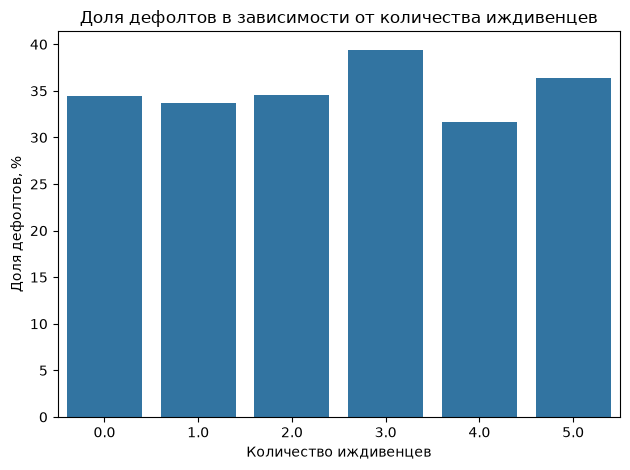

In [292]:
# Рассчитываем количество клиентов и долю дефолтов

dependents_stats = (df_train_10.groupby("dependents", observed=True)
    .agg(clients_count=("target", "count"),default_rate=("target", "mean")).reset_index())
dependents_stats["default_rate"] *= 100
print(dependents_stats)

# График
sns.barplot(data=dependents_stats, x="dependents", y="default_rate")

plt.title("Доля дефолтов в зависимости от количества иждивенцев")
plt.xlabel("Количество иждивенцев")
plt.ylabel("Доля дефолтов, %")
plt.tight_layout()
plt.show()

In [293]:
# eda = df_train_10.dropna(subset=["target", "monthly_income", "education"]).copy()

# # Делим доход на 5 групп по квантилям
# eda["income_group"] = pd.qcut(
#     eda["monthly_income"],
#     q=5,
#     duplicates="drop"
# )

# # Строим таблицу доли дефолтов
# income_education = eda.pivot_table(
#     index="education",
#     columns="income_group",
#     values="target",
#     aggfunc="mean",
#     observed=True
# ) * 100

# print(income_education.round(2))

# # Тепловая карта
# sns.heatmap(
#     income_education,
#     annot=True,
#     fmt=".1f",
#     cmap="YlOrRd"
# )

# plt.title("Доля дефолтов по уровню образования и доходу")
# plt.xlabel("Группа дохода")
# plt.ylabel("Образование")
# plt.tight_layout()
# plt.show()

<Axes: xlabel='education', ylabel='target'>

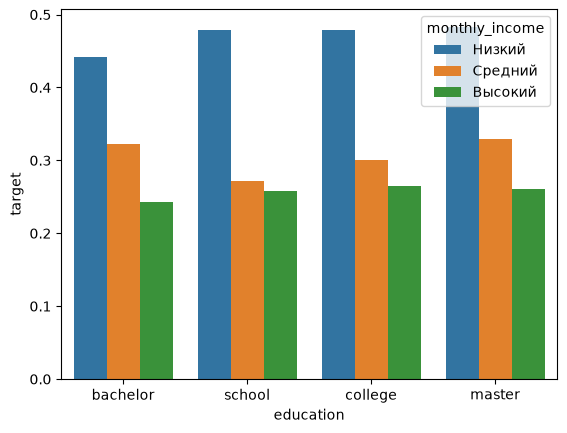

In [294]:
income_group = pd.qcut(df_train_10["monthly_income"],q=3,labels=["Низкий", "Средний", "Высокий"])

sns.barplot(
    data=df_train_10,
    x="education",
    y="target",
    hue=income_group,
    errorbar=None
)


Доля дефолта почти не зависит от уровня образования заемщика. Она больше зависит именно от уровня дохода и зависит линейно. Чем меньше заработок тем больше дефолтов. 

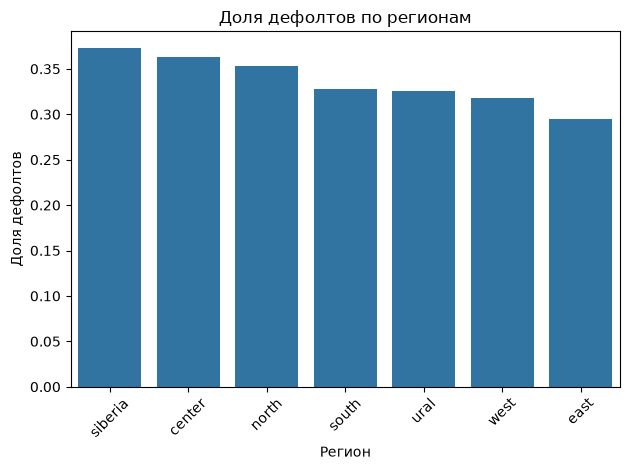

In [295]:
sns.barplot(
    data=df_train_10,
    x="region",
    y="target",
    errorbar=None,
    order=df_train_10.groupby("region")["target"]
        .mean()
        .sort_values(ascending=False)
        .index
)

plt.title("Доля дефолтов по регионам")
plt.xlabel("Регион")
plt.ylabel("Доля дефолтов")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Больше всего дефолтов в сибири и в центре России. Но зависимость незначительна чтобы делать полезные бизнесу выводы. 

### Какие продукты выбирают разные маркетинговые сегменты?

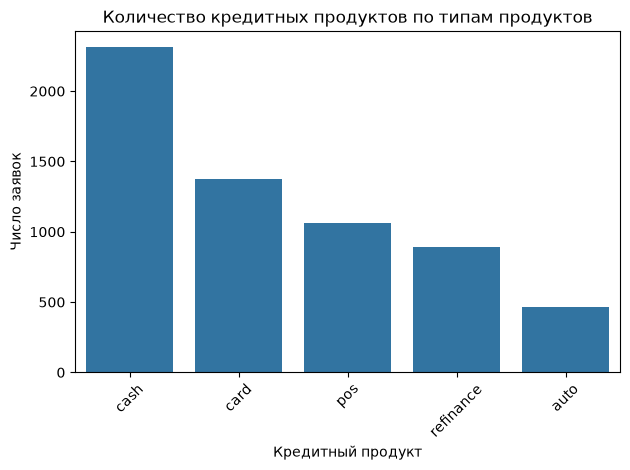

In [296]:
sns.countplot(
    data=df_train_10,
    x="requested_product",
    order=df_train_10["requested_product"].value_counts().index
)

plt.title("Количество кредитных продуктов по типам продуктов")
plt.xlabel("Кредитный продукт")
plt.ylabel("Число заявок")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Больше всего берут кредит на деньги

### Сумма кредита по продуктам

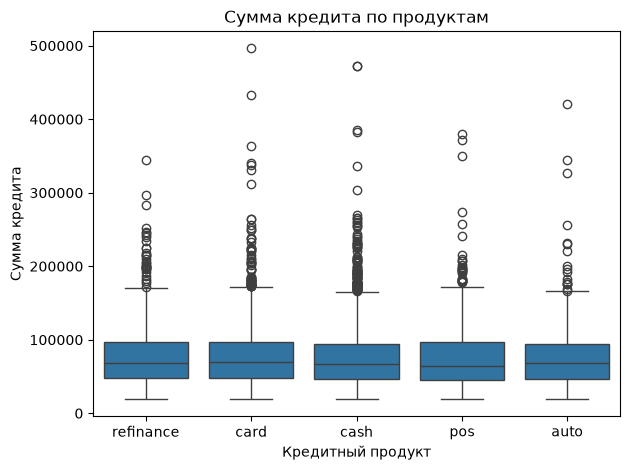

In [297]:
sns.boxplot(
    data=df_train_10,
    x="requested_product",
    y="loan_amount"
)

plt.title("Сумма кредита по продуктам")
plt.xlabel("Кредитный продукт")
plt.ylabel("Сумма кредита")
plt.tight_layout()
plt.show()

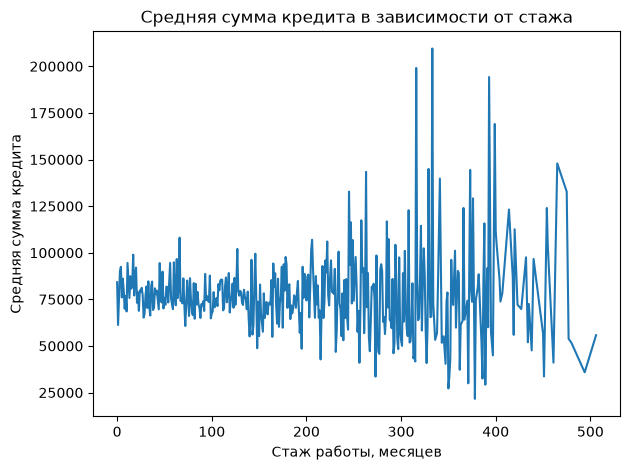

In [298]:
sns.lineplot(
    data=df_train_10,
    x="months_at_job",
    y="loan_amount",
    estimator="mean",
    errorbar=None
)

plt.title("Средняя сумма кредита в зависимости от стажа")
plt.xlabel("Стаж работы, месяцев")
plt.ylabel("Средняя сумма кредита")
plt.tight_layout()
plt.show()

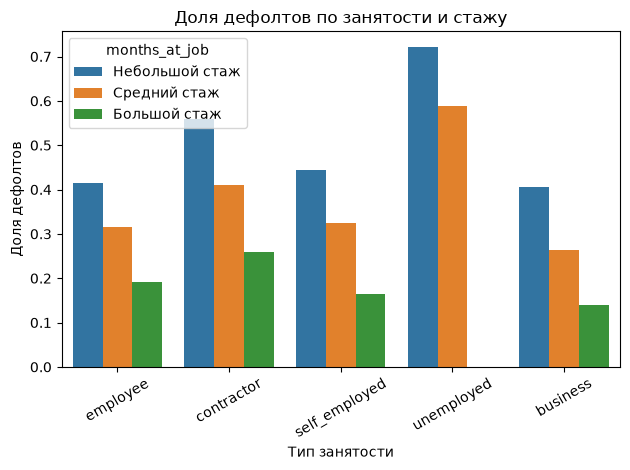

In [299]:
tenure_group = pd.qcut(
    df_train_10["months_at_job"],
    q=3,
    labels=["Небольшой стаж", "Средний стаж", "Большой стаж"]
)

sns.barplot(
    x=df_train_10["employment_type"],
    y=df_train_10["target"],
    hue=tenure_group,
    errorbar=None
)

plt.title("Доля дефолтов по занятости и стажу")
plt.xlabel("Тип занятости")
plt.ylabel("Доля дефолтов")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

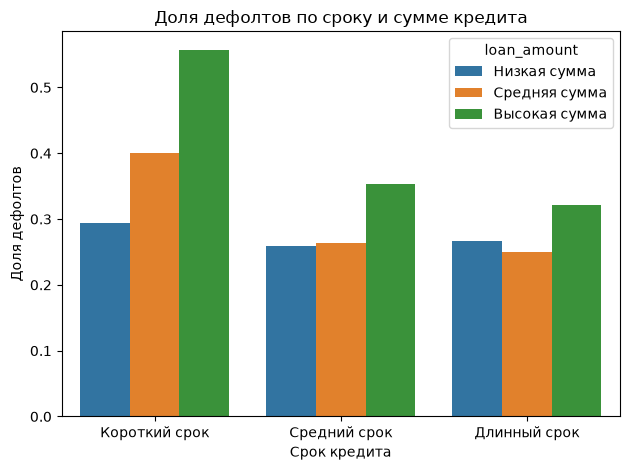

In [300]:
loan_group = pd.qcut(
    df_train_10["loan_amount"],
    q=3,
    labels=["Низкая сумма", "Средняя сумма", "Высокая сумма"]
)

term_group = pd.qcut(
    df_train_10["loan_term_months"],
    q=3,
    labels=["Короткий срок", "Средний срок", "Длинный срок"]
)

sns.barplot(
    x=term_group,
    y=df_train_10["target"],
    hue=loan_group,
    errorbar=None
)

plt.title("Доля дефолтов по сроку и сумме кредита")
plt.xlabel("Срок кредита")
plt.ylabel("Доля дефолтов")
plt.tight_layout()
plt.show()

In [301]:
df_train_10.info()

<class 'pandas.DataFrame'>
RangeIndex: 6488 entries, 0 to 6487
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                6039 non-null   float64
 1   monthly_income     6047 non-null   float64
 2   employment_type    6023 non-null   str    
 3   months_at_job      6102 non-null   float64
 4   education          6040 non-null   str    
 5   loan_amount        5932 non-null   float64
 6   loan_term_months   5961 non-null   float64
 7   dependents         6018 non-null   float64
 8   region             5942 non-null   str    
 9   requested_product  6106 non-null   str    
 10  target             6488 non-null   int64  
dtypes: float64(6), int64(1), str(4)
memory usage: 713.0 KB


In [302]:
df_train_10.drop_duplicates(inplace=True)

In [303]:
df_train_10.select_dtypes(include=["object"]).isna().sum()

/tmp/ipykernel_2175/3601982776.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_train_10.select_dtypes(include=["object"]).isna().sum()


employment_type      465
education            448
region               545
requested_product    382
dtype: int64

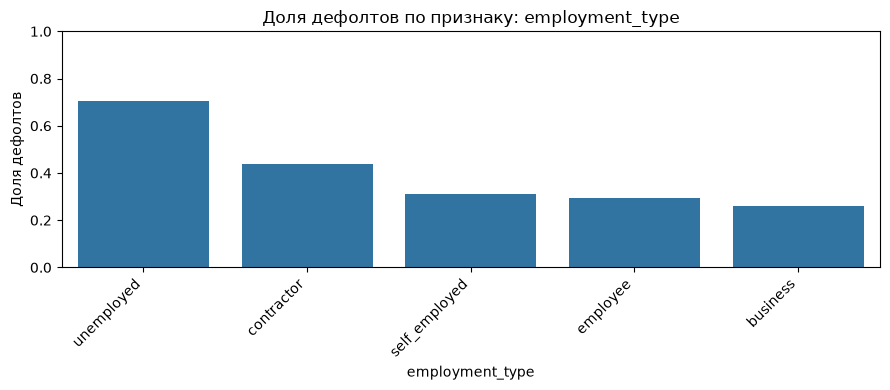

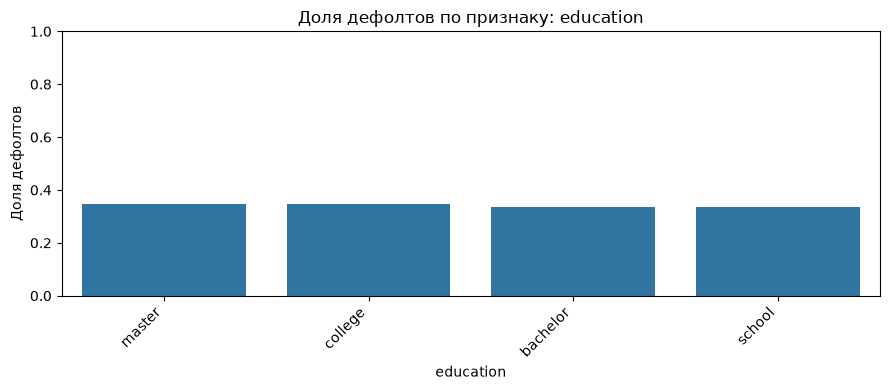

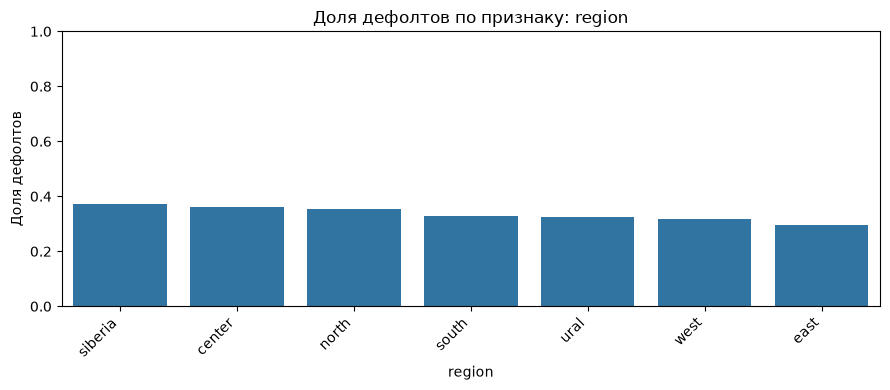

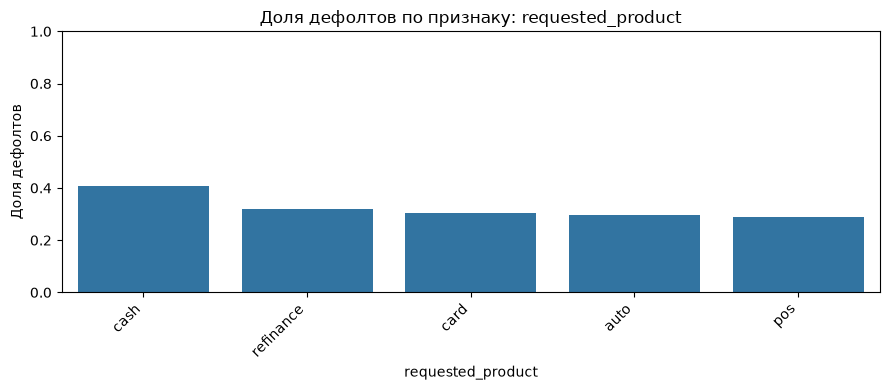

In [304]:
# Целевая переменная: 1 — дефолт, 0 — нет дефолта
target_col = "target"

# Категориальные признаки
cat_cols = df_train_10.select_dtypes(
    include=["object", "category", "string"]
).columns.drop(target_col, errors="ignore")

for col in cat_cols:
    # Считаем долю дефолтов в каждой категории
    rates = df_train_10.groupby(
        col, dropna=False
    )[target_col].mean().sort_values(ascending=False)

    plt.figure(figsize=(9, 4))
    sns.barplot(x=rates.index.astype(str), y=rates.values)

    plt.title(f"Доля дефолтов по признаку: {col}")
    plt.xlabel(col)
    plt.ylabel("Доля дефолтов")
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

In [305]:
# cat_cols = df_train_10.select_dtypes(include=["object"]).columns
# # Строки с NaN хотя бы в одном категориальном столбце
# rows_to_drop = df_train_10[cat_cols].isna().any(axis=1)

# print("Всего строк:", len(df_train_10))
# print("Строк с NaN в категориальных признаках:", rows_to_drop.sum())
# print("Доля потерь, %:", round(rows_to_drop.mean() * 100, 2))
# print("Останется строк:", len(df_train_10) - rows_to_drop.sum())

In [306]:
df_train_10.info()

<class 'pandas.DataFrame'>
RangeIndex: 6480 entries, 0 to 6479
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                6031 non-null   float64
 1   monthly_income     6041 non-null   float64
 2   employment_type    6015 non-null   str    
 3   months_at_job      6094 non-null   float64
 4   education          6032 non-null   str    
 5   loan_amount        5924 non-null   float64
 6   loan_term_months   5955 non-null   float64
 7   dependents         6012 non-null   float64
 8   region             5935 non-null   str    
 9   requested_product  6098 non-null   str    
 10  target             6480 non-null   int64  
dtypes: float64(6), int64(1), str(4)
memory usage: 712.1 KB


In [307]:
# Доля пропусков по каждому столбцу
missing = pd.DataFrame({
    "count": df_train_10.isna().sum(),
    "percent": df_train_10.isna().mean() * 100
})

print(missing.sort_values("percent", ascending=False).round(2))

# Сколько строк имеют хотя бы один пропуск
rows_with_missing = df_train_10.isna().any(axis=1).sum()

print("Строк с пропусками:", rows_with_missing)
print(
    "Доля строк с пропусками, %:",
    round(rows_with_missing / len(df_train_10) * 100, 2)
)

                   count  percent
loan_amount          556     8.58
region               545     8.41
loan_term_months     525     8.10
dependents           468     7.22
employment_type      465     7.18
age                  449     6.93
education            448     6.91
monthly_income       439     6.77
months_at_job        386     5.96
requested_product    382     5.90
target                 0     0.00
Строк с пропусками: 3416
Доля строк с пропусками, %: 52.72


In [308]:
# Количество пропусков в каждой строке
missing_per_row = (df_train_10.isna().mean(axis=1)*100).sort_values(ascending=False).round(2)

# Первые 15 строк с максимальным количеством пропусков
print(
    missing_per_row.head(25)
)

2431    36.36
879     36.36
4409    36.36
4419    36.36
4473    36.36
1596    36.36
886     36.36
5142    36.36
1608    36.36
3605    36.36
1321    36.36
2764    36.36
1130    36.36
5888    36.36
3113    36.36
650     27.27
4522    27.27
4511    27.27
619     27.27
6044    27.27
6008    27.27
134     27.27
3664    27.27
2258    27.27
529     27.27
dtype: float64


In [309]:
df_train_10 

,age,monthly_income,employment_type,months_at_job,education,loan_amount,loan_term_months,dependents,region,requested_product,target
0,37.0,30401.28,employee,31.0,bachelor,63464.49,24.0,0.0,east,refinance,1
1,60.0,26024.64,employee,90.0,school,113513.59,6.0,0.0,ural,card,1
2,37.0,21389.83,contractor,57.0,college,48993.42,9.0,1.0,west,cash,0
3,NaN,NaN,NaN,19.0,college,77765.78,36.0,0.0,ural,card,0
4,60.0,18000.00,employee,405.0,bachelor,97254.10,9.0,0.0,west,card,0
...,...,...,...,...,...,...,...,...,...,...,...
6475,57.0,73649.90,business,97.0,bachelor,NaN,12.0,0.0,south,pos,0
6476,26.0,45892.80,self_employed,25.0,college,31477.13,6.0,1.0,east,cash,0
6477,40.0,46981.28,self_employed,109.0,school,114445.95,48.0,1.0,south,refinance,0
6478,49.0,31108.33,employee,136.0,master,138748.57,18.0,3.0,west,cash,1


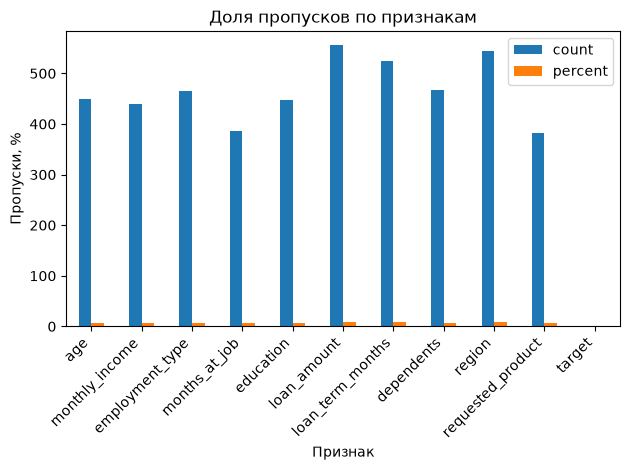

In [310]:
missing = missing[missing > 0]

missing.plot(kind="bar")

plt.title("Доля пропусков по признакам")
plt.xlabel("Признак")
plt.ylabel("Пропуски, %")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

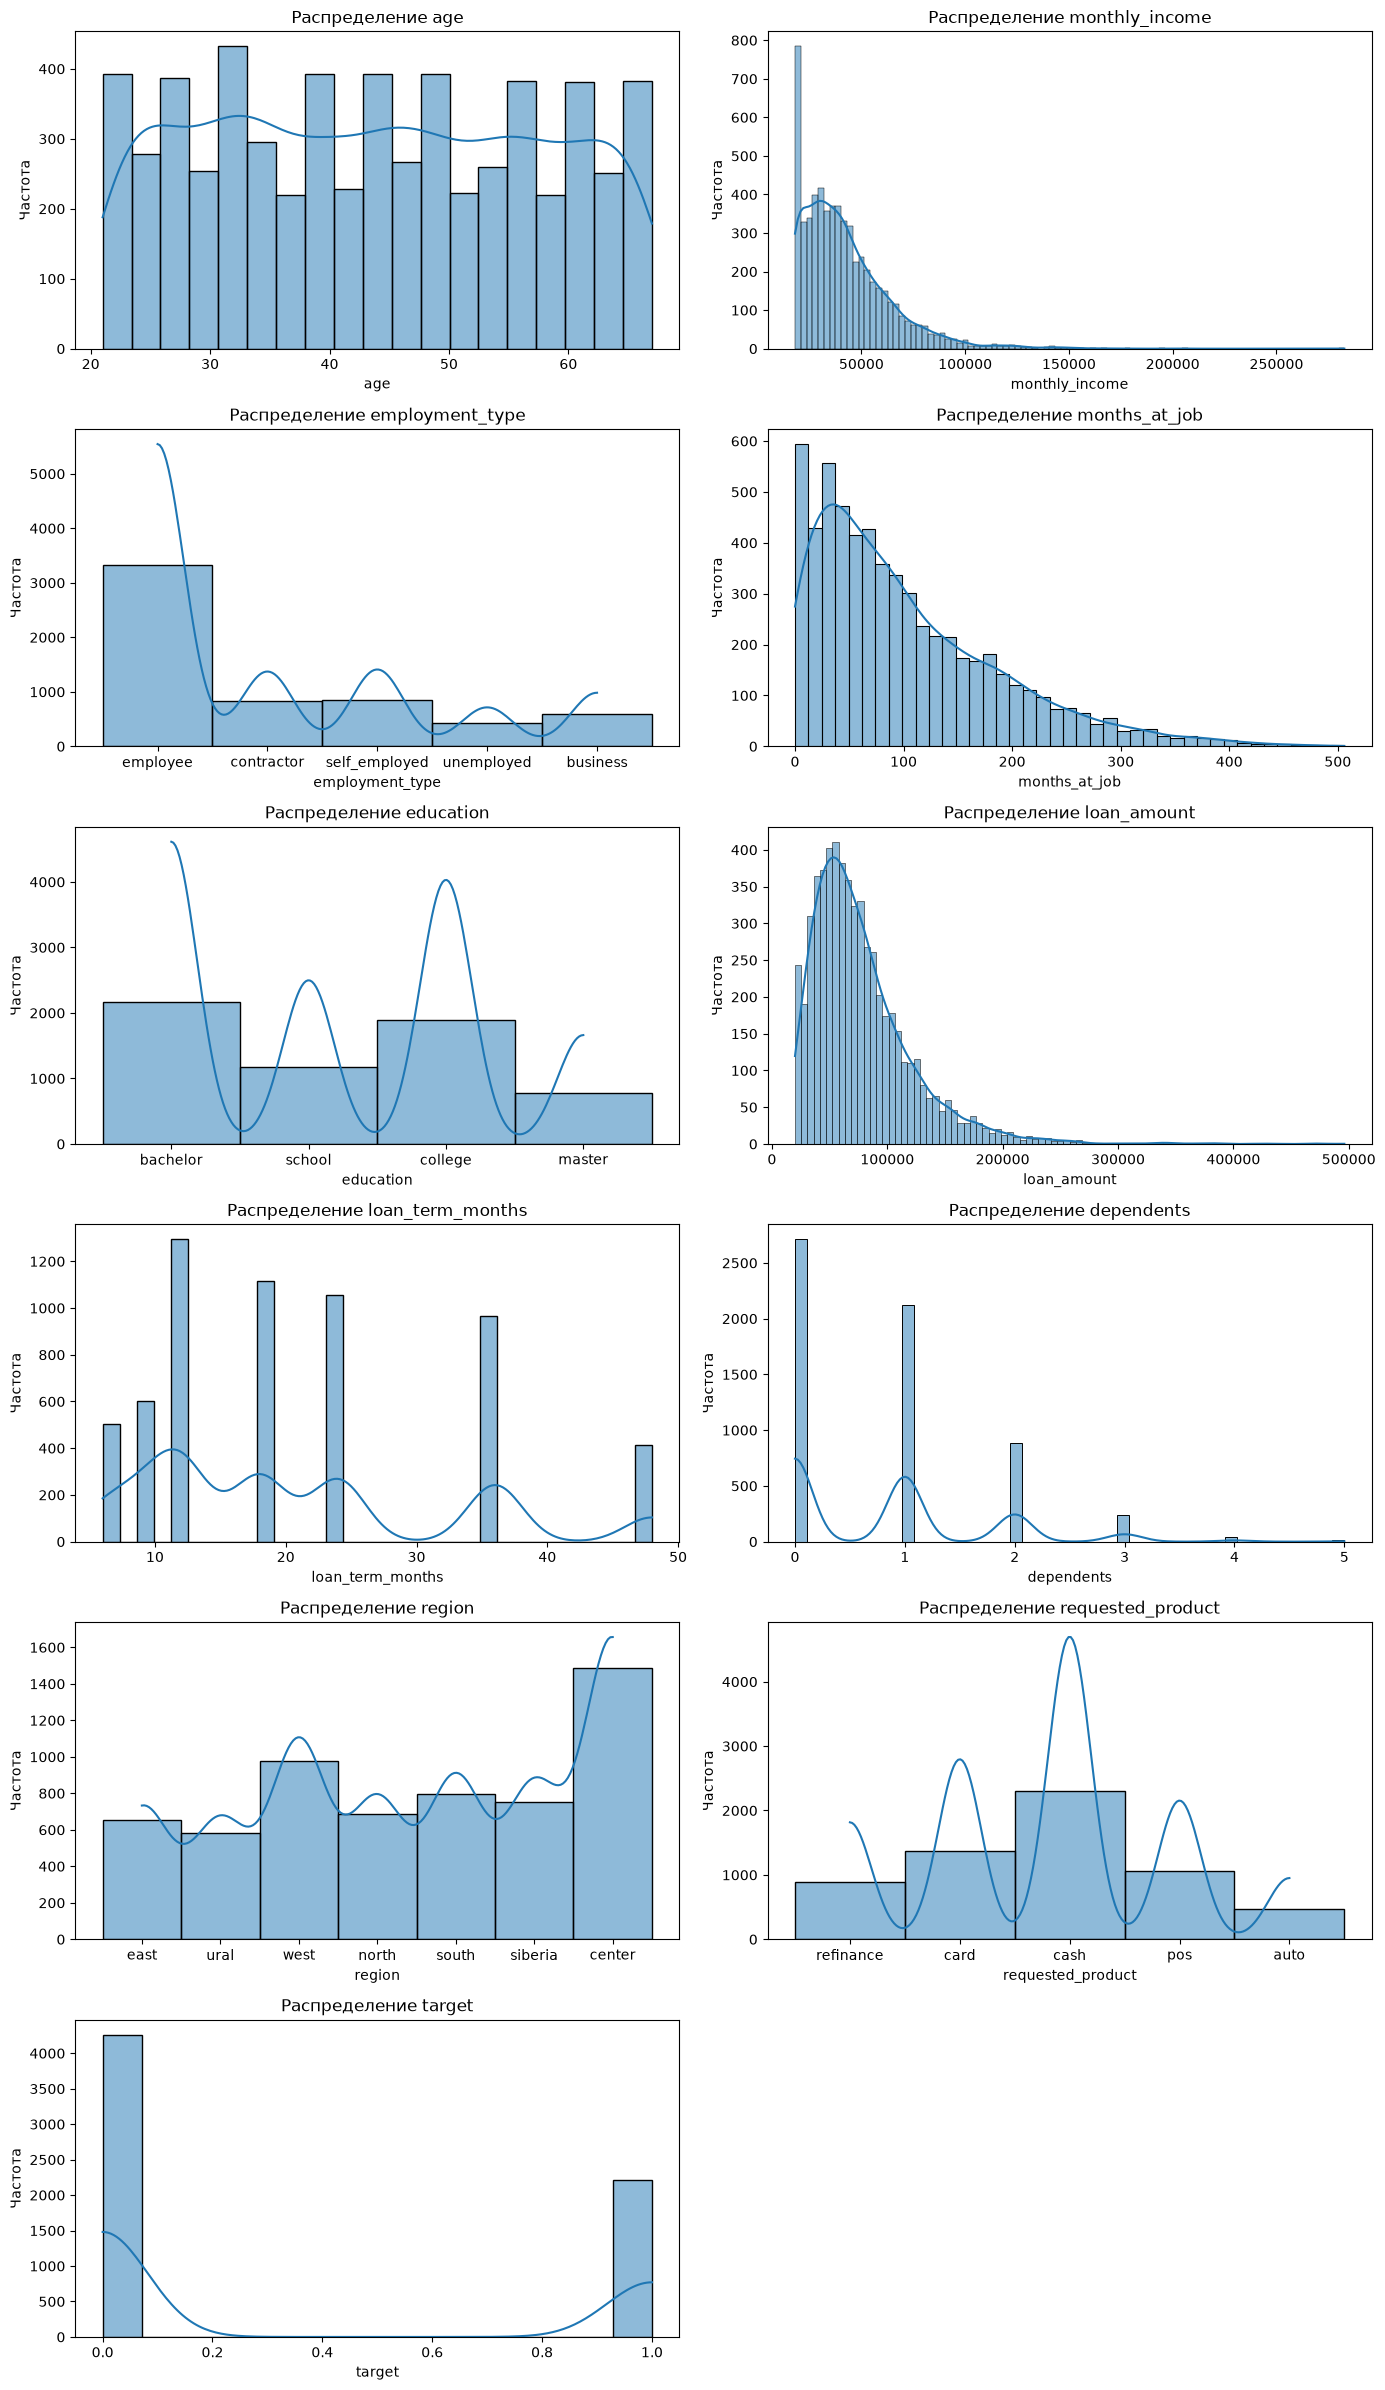

In [311]:
# for col in df_train_10.columns:
#     sns.histplot(kde=True, data=df_train_10, x=col)
#     plt.title(f"Распределение {col}")
#     plt.xlabel(col)
#     plt.ylabel("Частота")
#     plt.show()
    

cols = df_train_10.columns
n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(data=df_train_10, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Распределение {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Частота")

# Удаляем пустые области, если число графиков нечётное
for i in range(len(cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

### Заполнение пропусков 

In [312]:
df_train_10['age'] = df_train_10['age'].fillna(df_train_10['age'].mean())
df_train_10['loan_term_months'] = df_train_10['loan_term_months'].fillna(df_train_10['loan_term_months'].mean())

In [313]:
cols = ['monthly_income','loan_amount','months_at_job',"dependents"]
for col in cols:
    median = df_train_10[col].median()
    df_train_10[col] = df_train_10[col].fillna(median)

In [314]:
cat_cols = ["education", "employment_type", "region", "requested_product"]

for col in cat_cols:
    df_train_10[col] = df_train_10[col].fillna("Unknown")

In [315]:
df_train_10.isnull().sum()

age                  0
monthly_income       0
employment_type      0
months_at_job        0
education            0
loan_amount          0
loan_term_months     0
dependents           0
region               0
requested_product    0
target               0
dtype: int64

### Визуализируем выбросы каждой колонки 

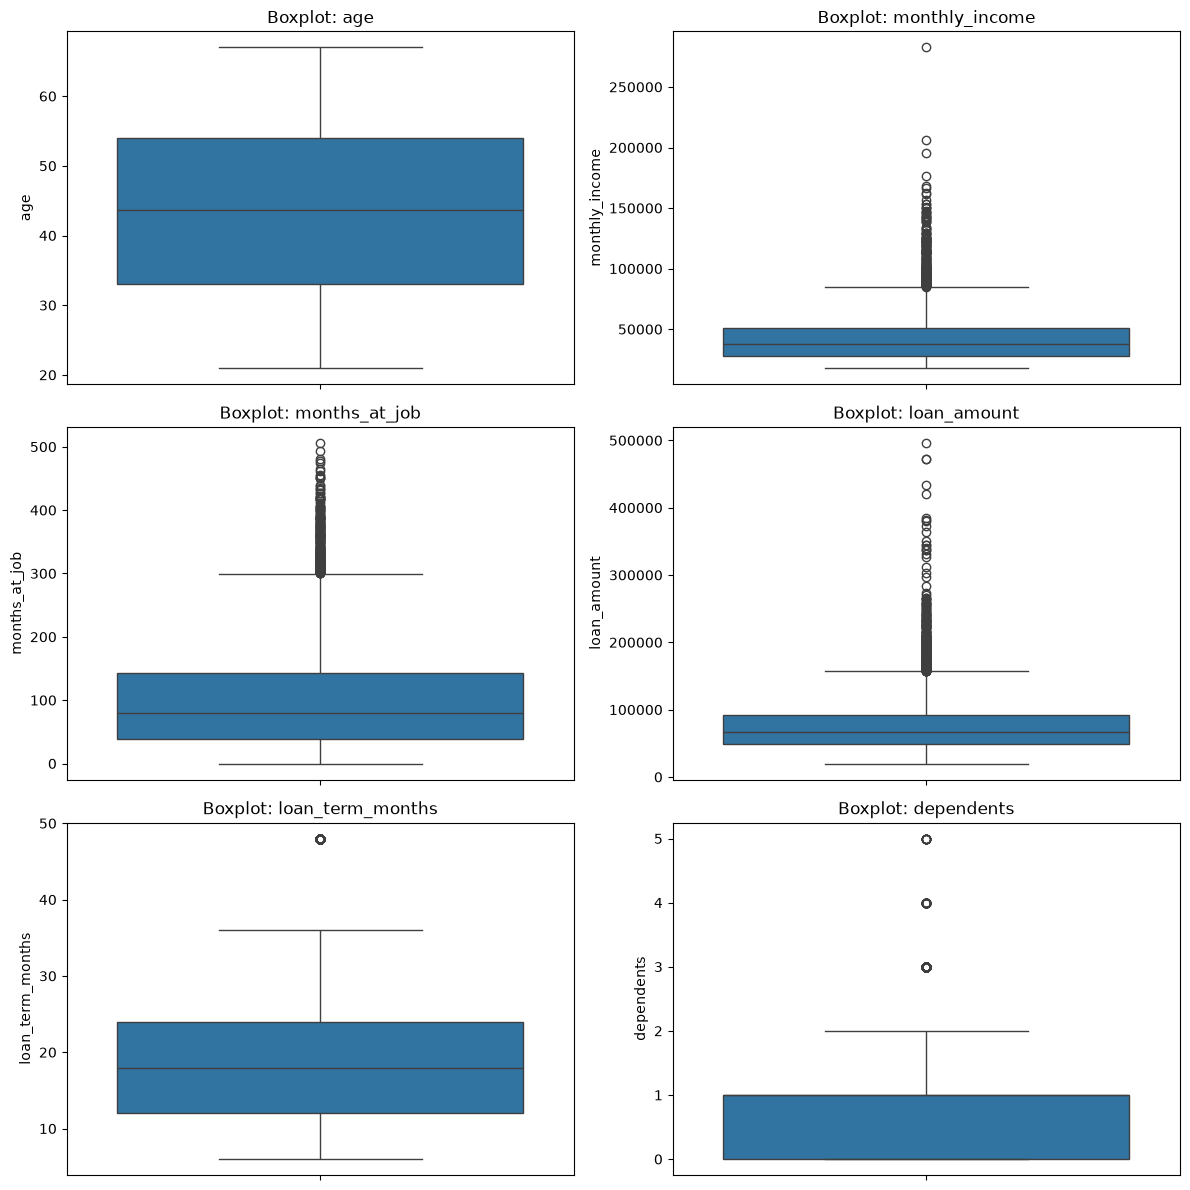

In [316]:
cols = df_train_10.select_dtypes(include=np.number).drop(columns=['target']).columns
n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(nrows=n_rows,ncols=n_cols,figsize=(12, 4 * n_rows))

axes = axes.flatten()

for idx, feat in enumerate(cols):
    sns.boxplot(y=df_train_10[feat], ax=axes[idx])
    axes[idx].set_title(f"Boxplot: {feat}")
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel(feat)

for idx in range(len(cols), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

### IQR method для удаления пропусков 

In [317]:
cols_outliers = ['monthly_income', 'loan_amount', 'months_at_job']
for col in cols_outliers:
    Q1 = df_train_10[col].quantile(0.25)
    Q3 = df_train_10[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_train_10[col] = df_train_10[col].clip(lower, upper)

### Проверка редких категорий

In [318]:
cat_cols = ["education", "employment_type", "region", "requested_product"]  
for col in cat_cols:
    freq = df_train_10[col].value_counts(normalize=True)
    print(col, freq)

education education
bachelor    0.335340
college     0.293056
school      0.181636
master      0.120833
Unknown     0.069136
Name: proportion, dtype: float64
employment_type employment_type
employee         0.513426
self_employed    0.130556
contractor       0.127006
business         0.091049
Unknown          0.071759
unemployed       0.066204
Name: proportion, dtype: float64
region region
center     0.229630
west       0.150926
south      0.122994
siberia    0.116358
north      0.105556
east       0.100772
ural       0.089660
Unknown    0.084105
Name: proportion, dtype: float64
requested_product requested_product
cash         0.356173
card         0.211883
pos          0.163272
refinance    0.137654
auto         0.072068
Unknown      0.058951
Name: proportion, dtype: float64


### Поиск лишних пробелов

In [319]:
for col in cat_cols:
    s = df_train_10[col]
    if s.map(lambda x: isinstance(x, str)).all():
        bad = s[s != s.str.strip()]
        if not bad.empty:
            print(col, bad.unique())

### Поиск различий в регистре

In [320]:
for col in cat_cols:
    s = df_train_10[col].dropna().astype(str)
    groups = s.groupby(s.str.strip().str.lower()).unique()
    print(col, groups[groups.map(len) > 1])

education Series([], Name: education, dtype: object)
employment_type Series([], Name: employment_type, dtype: object)
region Series([], Name: region, dtype: object)
requested_product Series([], Name: requested_product, dtype: object)


### Поиск пропусков и аномальных маркеров

In [321]:
for col in cat_cols:
    s = df_train_10[col].astype("string").str.strip().str.lower()

    missing = s.isna() | s.isin(["", "n/a", "null", "none"])

    if missing.any():
        print(col, "Проблемных значений:", missing.sum())

In [322]:
df_train_10_for_encoding = df_train_10.copy()

### Кодирование категориальных признаков 

In [323]:
ord_enc = OrdinalEncoder(
    categories=[["school", "college", "bachelor", "master"]],
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    encoded_missing_value=-1
)
df_train_10_for_encoding["education"] = df_train_10_for_encoding["education"].replace(
    "Unknown", float("nan")
)

ord_enc.fit(df_train_10_for_encoding[["education"]])

df_train_10_for_encoding["education_enc"] = ord_enc.transform(
    df_train_10_for_encoding[["education"]]
).ravel()




In [324]:
df_train_10_for_encoding.drop(columns = "education", inplace=True)
df_train_10_for_encoding["education_enc"].unique()

array([ 2.,  0.,  1., -1.,  3.])

In [325]:
df_train_10_for_encoding

,age,monthly_income,employment_type,months_at_job,loan_amount,loan_term_months,dependents,region,requested_product,target,education_enc
0,37.000000,30401.28,employee,31.0,63464.49,24.0,0.0,east,refinance,1,2.0
1,60.000000,26024.64,employee,90.0,113513.59,6.0,0.0,ural,card,1,0.0
2,37.000000,21389.83,contractor,57.0,48993.42,9.0,1.0,west,cash,0,1.0
3,43.634389,37717.51,Unknown,19.0,77765.78,36.0,0.0,ural,card,0,1.0
4,60.000000,18000.00,employee,299.0,97254.10,9.0,0.0,west,card,0,2.0
...,...,...,...,...,...,...,...,...,...,...,...
6475,57.000000,73649.90,business,97.0,67331.28,12.0,0.0,south,pos,0,2.0
6476,26.000000,45892.80,self_employed,25.0,31477.13,6.0,1.0,east,cash,0,1.0
6477,40.000000,46981.28,self_employed,109.0,114445.95,48.0,1.0,south,refinance,0,0.0
6478,49.000000,31108.33,employee,136.0,138748.57,18.0,3.0,west,cash,1,3.0


In [326]:
ohe_enc = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

cols_cat_ohe = ["employment_type", "region", "requested_product"]

ohe_enc.fit(df_train_10_for_encoding[cols_cat_ohe])

train_encoded = ohe_enc.transform(df_train_10_for_encoding[cols_cat_ohe])
# test_encoded = ohe_enc.transform(df_test[cols_cat_ohe])

# Создаём DataFrame с названиями новых признаков
encoded_cols_cat_ohe = ohe_enc.get_feature_names_out(cols_cat_ohe)

train_encoded_df = pd.DataFrame(
    train_encoded,
    columns=encoded_cols_cat_ohe,
    index=df_train_10_for_encoding.index
)

# test_encoded_df = pd.DataFrame(
#     test_encoded,
#     columns=encoded_cols_cat_ohe,
#     index=df_test.index
# )

# Добавляем новые признаки и удаляем исходные категориальные
df_train_10_for_encoding = pd.concat(
    [df_train_10_for_encoding.drop(columns=cols_cat_ohe), train_encoded_df], axis=1
)

# df_test = pd.concat(
#     [df_test.drop(columns=cols_cat_ohe), test_encoded_df], axis=1
# )


In [327]:
df_train_10_for_encoding

,age,monthly_income,months_at_job,loan_amount,loan_term_months,dependents,target,education_enc,employment_type_Unknown,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,region_Unknown,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west,requested_product_Unknown,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance
0,37.000000,30401.28,31.0,63464.49,24.0,0.0,1,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,60.000000,26024.64,90.0,113513.59,6.0,0.0,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,37.000000,21389.83,57.0,48993.42,9.0,1.0,0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,43.634389,37717.51,19.0,77765.78,36.0,0.0,0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,60.000000,18000.00,299.0,97254.10,9.0,0.0,0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6475,57.000000,73649.90,97.0,67331.28,12.0,0.0,0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6476,26.000000,45892.80,25.0,31477.13,6.0,1.0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6477,40.000000,46981.28,109.0,114445.95,48.0,1.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6478,49.000000,31108.33,136.0,138748.57,18.0,3.0,1,3.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


Correlation_matrix

<Axes: >

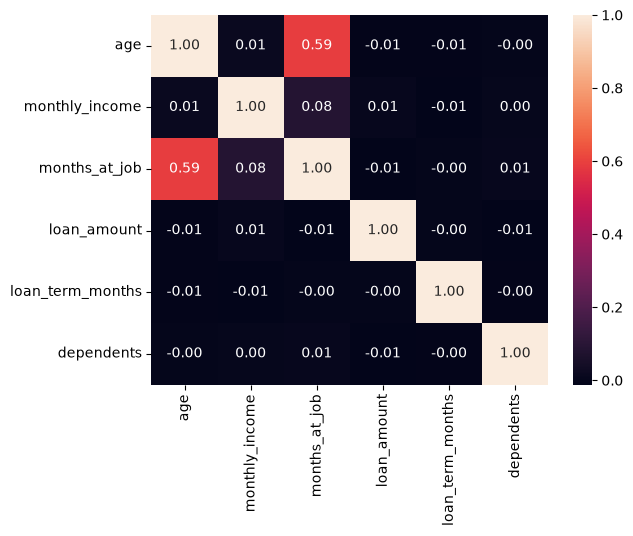

In [328]:
df_train_10_numeric = df_train_10.select_dtypes(include=np.number).drop(columns=['target'])
corr_matrix = df_train_10_numeric.corr()
sns.heatmap(corr_matrix, annot=True,fmt=".2f")

### Подгрузим df_test_10

In [256]:
df_test = pd.read_sql(
    "SELECT * FROM test",
    engine
)

df_test.head()

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,post_loan_collection_score,months_at_job,channel,education,internal_decision_code,monthly_income,region,employment_type,days_until_first_overdue,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,requested_product,application_date
0,102531,2531,0.0,18.0,NaN,NaN,73071.51,None,38.0,call_center,bachelor,None,34183.79,east,employee,None,34183.79,NaN,0.0,0.2146,segment_112,1.0,refinance,2025-04-25
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,None,23.0,partner,school,None,18645.00,north,unemployed,None,18645.00,64.0,0.0,0.2851,segment_023,1.0,refinance,2025-05-07
2,100238,238,0.0,36.0,0.902039,92419982.0,NaN,None,12.0,office,bachelor,None,52931.84,ural,employee,None,52931.84,21.0,1.0,0.3810,segment_020,1.0,card,2025-02-26
3,104918,4918,0.0,6.0,0.737848,76137566.0,NaN,None,179.0,web,college,None,NaN,center,employee,None,37301.16,55.0,0.0,0.1471,segment_057,1.0,auto,2025-12-07
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,None,153.0,mobile,bachelor,None,71928.29,center,NaN,None,71928.29,55.0,1.0,0.1840,segment_138,1.0,cash,2025-05-09


In [329]:
df_test_10 = df_test[["age","monthly_income", "employment_type","months_at_job", "education","loan_amount","loan_term_months","dependents", "region", "requested_product"]]
df_test_10

,age,monthly_income,employment_type,months_at_job,education,loan_amount,loan_term_months,dependents,region,requested_product
0,NaN,34183.79,employee,38.0,bachelor,73071.51,18.0,0.0,east,refinance
1,64.0,18645.00,unemployed,23.0,school,65408.73,12.0,0.0,north,refinance
2,21.0,52931.84,employee,12.0,bachelor,NaN,36.0,1.0,ural,card
3,55.0,NaN,employee,179.0,college,NaN,6.0,0.0,center,auto
4,55.0,71928.29,NaN,153.0,bachelor,76253.20,12.0,1.0,center,cash
...,...,...,...,...,...,...,...,...,...,...
2515,NaN,34557.28,employee,200.0,college,95337.81,24.0,1.0,north,cash
2516,41.0,47207.94,self_employed,206.0,school,NaN,9.0,2.0,siberia,cash
2517,25.0,25281.07,employee,48.0,college,63097.47,36.0,1.0,ural,auto
2518,31.0,30665.10,employee,90.0,college,148171.13,12.0,1.0,center,pos


In [330]:
df_test_10.info()

<class 'pandas.DataFrame'>
RangeIndex: 2520 entries, 0 to 2519
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                2322 non-null   float64
 1   monthly_income     2284 non-null   float64
 2   employment_type    2365 non-null   str    
 3   months_at_job      2329 non-null   float64
 4   education          2345 non-null   str    
 5   loan_amount        2351 non-null   float64
 6   loan_term_months   2360 non-null   float64
 7   dependents         2365 non-null   float64
 8   region             2284 non-null   str    
 9   requested_product  2328 non-null   str    
dtypes: float64(6), str(4)
memory usage: 257.3 KB


In [331]:
missing_percent_cols = df_test_10.isna().mean() * 100


print(missing_percent_cols.sort_values(ascending=False))

missing_percent_rows = df_test_10.isna().mean(axis=1) * 100

print(missing_percent_rows[missing_percent_rows > 39].sort_values(ascending=False))
# df_missing = df_test_10.loc[missing_percent_rows > 39]

# display(df_missing)

monthly_income       9.365079
region               9.365079
age                  7.857143
requested_product    7.619048
months_at_job        7.579365
education            6.944444
loan_amount          6.706349
loan_term_months     6.349206
employment_type      6.150794
dependents           6.150794
dtype: float64
2366    50.0
236     40.0
90      40.0
699     40.0
769     40.0
1346    40.0
1033    40.0
1368    40.0
1839    40.0
2257    40.0
2499    40.0
dtype: float64


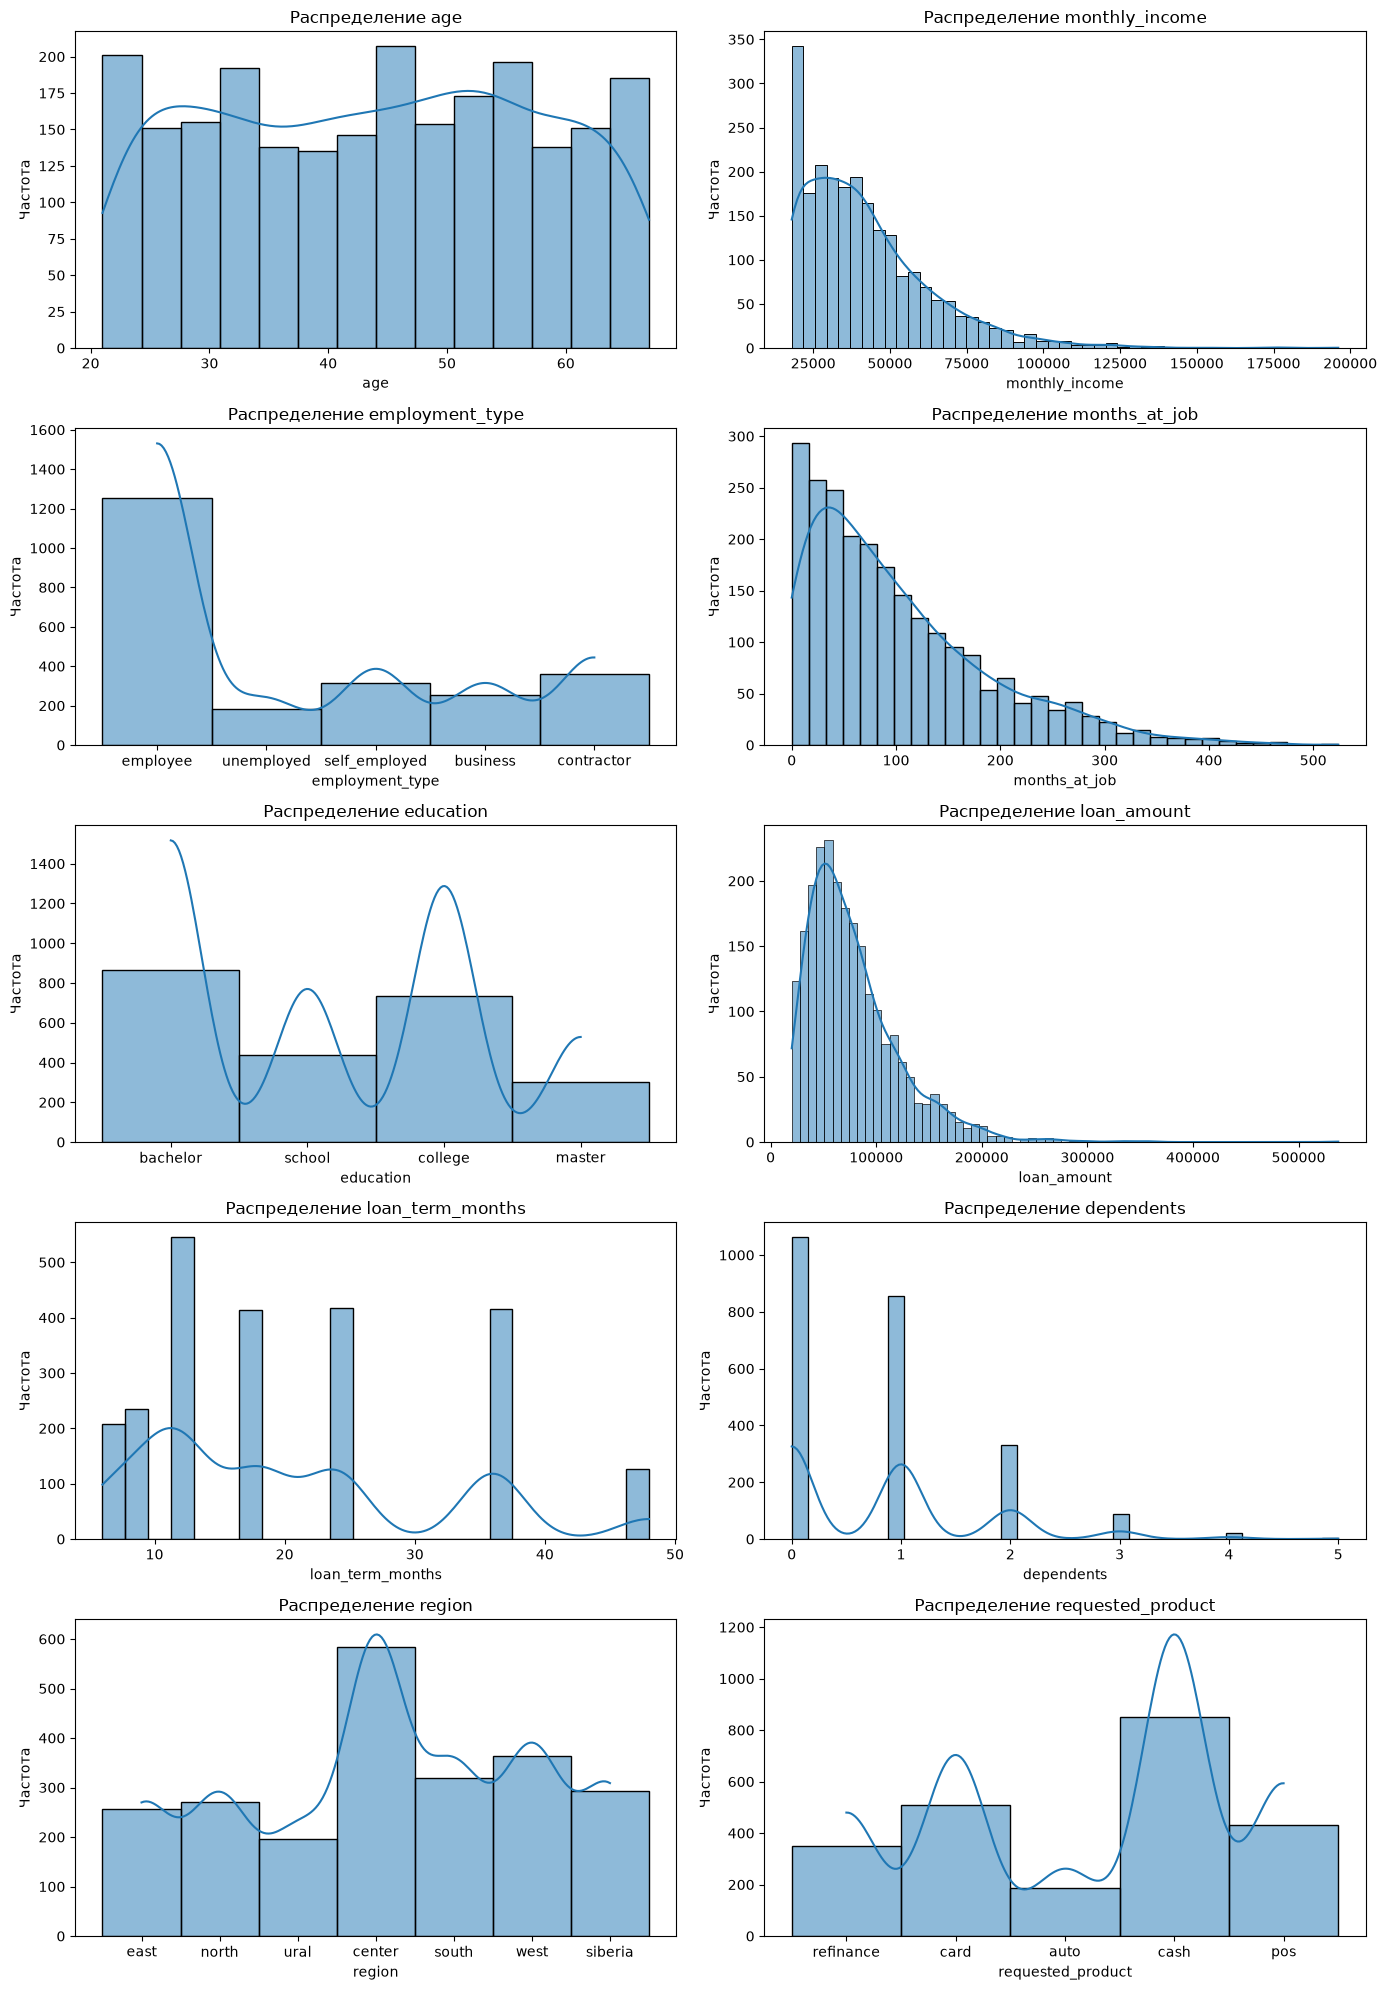

In [332]:
cols = df_test_10.columns
n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(data=df_test_10, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Распределение {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Частота")

# Удаляем пустые области, если число графиков нечётное
for i in range(len(cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [333]:
df_test_10['age'] = df_test_10['age'].fillna(df_test_10['age'].mean())
df_test_10['loan_term_months'] = df_test_10['loan_term_months'].fillna(df_test_10['loan_term_months'].mean())

In [334]:
cols = ['monthly_income','loan_amount','months_at_job',"dependents"]
for col in cols:
    median = df_test_10[col].median()
    df_test_10[col] = df_test_10[col].fillna(median)

In [335]:
cat_cols = ["education", "employment_type", "region", "requested_product"]

for col in cat_cols:
    df_test_10[col] = df_test_10[col].fillna("Unknown")

In [336]:
df_test_10.isna().sum()

age                  0
monthly_income       0
employment_type      0
months_at_job        0
education            0
loan_amount          0
loan_term_months     0
dependents           0
region               0
requested_product    0
dtype: int64

In [337]:
df_test_10_for_encoding = df_test_10.copy()

### Кодирование df_test_10

In [338]:
df_test_10_for_encoding["education_enc"] = ord_enc.transform(
    df_test_10_for_encoding[["education"]]
).ravel()

df_test_10_for_encoding.drop(columns = "education", inplace=True)
df_test_10_for_encoding["education_enc"].unique()

array([ 2.,  0.,  1.,  3., -1.])

In [340]:
cols_cat_ohe = ["employment_type", "region", "requested_product"]
test_encoded = ohe_enc.transform(df_test[cols_cat_ohe])

# Создаём DataFrame с названиями новых признаков
encoded_cols_cat_ohe = ohe_enc.get_feature_names_out(cols_cat_ohe)

test_encoded_df = pd.DataFrame(
    test_encoded,
    columns=encoded_cols_cat_ohe,
    index=df_test.index
)

# Добавляем новые признаки и удаляем исходные категориальные
df_test_10_for_encoding = pd.concat(
    [df_test_10_for_encoding.drop(columns=cols_cat_ohe), test_encoded_df], axis=1
)

In [341]:
df_test_10_for_encoding

,age,monthly_income,months_at_job,loan_amount,loan_term_months,dependents,education_enc,employment_type_Unknown,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,region_Unknown,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west,requested_product_Unknown,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance
0,43.946598,34183.790,38.0,73071.51,18.0,0.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,64.000000,18645.000,23.0,65408.73,12.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,21.000000,52931.840,12.0,67730.79,36.0,1.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,55.000000,37825.845,179.0,67730.79,6.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,55.000000,71928.290,153.0,76253.20,12.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2515,43.946598,34557.280,200.0,95337.81,24.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2516,41.000000,47207.940,206.0,67730.79,9.0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2517,25.000000,25281.070,48.0,63097.47,36.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2518,31.000000,30665.100,90.0,148171.13,12.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### Проведем Масштабирование 

In [342]:
df_train_10_for_encoding

,age,monthly_income,months_at_job,loan_amount,loan_term_months,dependents,target,education_enc,employment_type_Unknown,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,region_Unknown,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west,requested_product_Unknown,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance
0,37.000000,30401.28,31.0,63464.49,24.0,0.0,1,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,60.000000,26024.64,90.0,113513.59,6.0,0.0,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,37.000000,21389.83,57.0,48993.42,9.0,1.0,0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,43.634389,37717.51,19.0,77765.78,36.0,0.0,0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,60.000000,18000.00,299.0,97254.10,9.0,0.0,0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6475,57.000000,73649.90,97.0,67331.28,12.0,0.0,0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6476,26.000000,45892.80,25.0,31477.13,6.0,1.0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6477,40.000000,46981.28,109.0,114445.95,48.0,1.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6478,49.000000,31108.33,136.0,138748.57,18.0,3.0,1,3.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [348]:
X_train = df_train_10_for_encoding.drop(columns='target')
y_train = df_train_10_for_encoding['target']
y_train

0       1
1       1
2       0
3       0
4       0
       ..
6475    0
6476    0
6477    0
6478    1
6479    0
Name: target, Length: 6480, dtype: int64

In [366]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(df_test_10_for_encoding)

In [367]:
x_train_scaled

array([[-0.50562368, -0.59573824, -0.86827075, ..., -0.74378215,
        -0.44173629,  2.5029131 ],
       [ 1.24726488, -0.83956543, -0.11804413, ..., -0.74378215,
        -0.44173629, -0.39953445],
       [-0.50562368, -1.09777554, -0.53766241, ...,  1.34447969,
        -0.44173629, -0.39953445],
       ...,
       [-0.27698604,  0.32795089,  0.12355427, ..., -0.74378215,
        -0.44173629,  2.5029131 ],
       [ 0.40892688, -0.55634775,  0.46687832, ...,  1.34447969,
        -0.44173629, -0.39953445],
       [ 1.55211507, -1.14896341,  1.62400751, ..., -0.74378215,
        -0.44173629, -0.39953445]], shape=(6480, 27))

### Cross validation

In [371]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Создаём Logistic Regression и StandardScaler
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# 2. Настраиваем Cross-Validation на 5 фолдов
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Выбираем метрики оценки
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# 4. Выполняем Cross-Validation
cv_results = cross_validate(
    estimator=pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# 5. Выводим результаты по каждому фолду
results_df = pd.DataFrame({
    "ROC AUC": cv_results["test_roc_auc"],
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1": cv_results["test_f1"]
})

display(results_df.round(4))

# 6. Среднее и стандартное отклонение метрик
summary = pd.DataFrame({
    "Mean": results_df.mean(),
    "Std": results_df.std(ddof=0)
})

display(summary.round(4))

,ROC AUC,Accuracy,Precision,Recall,F1
0,0.7436,0.7191,0.6626,0.3671,0.4725
1,0.6954,0.7076,0.6285,0.3581,0.4562
2,0.7099,0.7045,0.6245,0.3446,0.4441
3,0.7335,0.7245,0.6604,0.3995,0.4979
4,0.7327,0.7261,0.6803,0.3747,0.4833


,Mean,Std
ROC AUC,0.7230,0.0177
Accuracy,0.7164,0.0088
Precision,0.6513,0.0214
Recall,0.3688,0.0183
F1,0.4708,0.0191


In [369]:
#instantiate the LinearRegression model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, auc

clf.fit(x_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [370]:
# ROC-AUC on train data: predict_proba returns shape (n_samples, 2)
# We need probabilities for the positive class only.
y_proba = clf.predict_proba(x_train_scaled)[:, 1]
roc_auc = roc_auc_score(y_train, y_proba)
print(f"Train ROC AUC: {roc_auc:.4f}")



Train ROC AUC: 0.7297


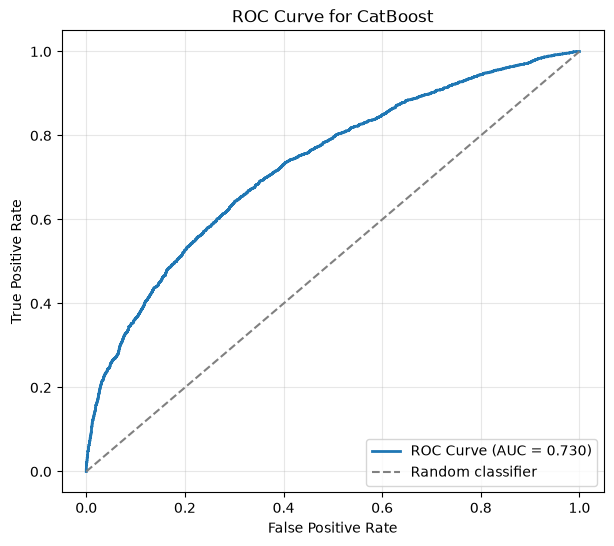

In [365]:
fpr, tpr, thresholds = roc_curve(y_train, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for CatBoost')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


In [ ]:
# df_test = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/test.csv')
# df_test

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,post_loan_collection_score,months_at_job,channel,...,employment_type,days_until_first_overdue,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,requested_product,application_date
0,102531,2531,0.0,18.0,NaN,NaN,73071.51,NaN,38.0,call_center,...,employee,NaN,34183.79,NaN,0.0,0.2146,segment_112,1.0,refinance,2025-04-25
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,NaN,23.0,partner,...,unemployed,NaN,18645.00,64.0,0.0,0.2851,segment_023,1.0,refinance,2025-05-07
2,100238,238,0.0,36.0,0.902039,92419982.0,NaN,NaN,12.0,office,...,employee,NaN,52931.84,21.0,1.0,0.3810,segment_020,1.0,card,2025-02-26
3,104918,4918,0.0,6.0,0.737848,76137566.0,NaN,NaN,179.0,web,...,employee,NaN,37301.16,55.0,0.0,0.1471,segment_057,1.0,auto,2025-12-07
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,NaN,153.0,mobile,...,NaN,NaN,71928.29,55.0,1.0,0.1840,segment_138,1.0,cash,2025-05-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2515,105735,5735,0.0,24.0,0.496285,17047133.0,95337.81,NaN,200.0,mobile,...,employee,NaN,34557.28,NaN,1.0,0.2745,segment_139,1.0,cash,2025-10-23
2516,105192,5192,0.0,9.0,0.940226,77377804.0,NaN,NaN,206.0,web,...,self_employed,NaN,NaN,41.0,2.0,0.1992,segment_097,1.0,cash,2025-01-19
2517,105391,5391,0.0,36.0,0.765447,NaN,63097.47,NaN,48.0,partner,...,employee,NaN,25281.07,25.0,1.0,0.3981,segment_057,1.0,auto,2025-10-10
2518,100861,861,0.0,12.0,0.826164,87976929.0,148171.13,NaN,90.0,call_center,...,employee,NaN,30665.10,31.0,1.0,0.2159,segment_123,1.0,pos,2025-05-18


### Проверим идентичны ли столбцы в Train и Test

In [60]:
df_train_cols = set(df_train.columns)
df_test_cols = set(df_test.columns)

if df_train_cols == df_test_cols:
    print("Столбцы идентичны")
else:
    print("Есть различия")

    print("\nЕсть только в df_train:")
    print(df_train_cols - df_test_cols)

    print("\nЕсть только в df_test:")
    print(df_test_cols - df_train_cols)

Есть различия

Есть только в df_train:
{'target'}

Есть только в df_test:
set()


# Добавление дополнительных таблиц к Train и Test

In [61]:
train_merged = df_train.merge(df_bureau_features,on='client_id',how='left')
train_merged = train_merged.merge(df_previous_features,on='client_id',how='left')
train_merged = train_merged.merge(df_transactions_features,on='client_id',how='left')
train_merged

,application_id,client_id,employment_type,hash_id,region_coefficient_extended,age,incoming_amount,internal_decision_code,monthly_income,application_date,education,requested_product,channel,loan_amount,marketing_segment,post_loan_collection_score,region_coefficient,region,interest_rate,months_at_job,dependents,days_until_first_overdue,loan_term_months,siberia_northern_score,target,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities
0,107941,7941,employee,61441390.0,1.0,37.0,30401.28,NaN,30401.28,2025-08-11,bachelor,refinance,partner,63464.49,segment_011,800.87,1.0,east,0.3062,31.0,0.0,61.0,24.0,0.336102,1,3.0,72210.10,24070.033333,148917.36,49639.120000,15.0,5.00,1594.0,1110.0,1.0,2.0,1.0,1.0,1.0,0.0,0.0,1.0,20623.70,20623.700,36.0,62.0,62.0,0.0,0.000000,0.0,0.0,35,-66394.98,-1896.999429,9444.87,-6075.02,2.171429,5.0,14936.68,-81331.66,7,3,1,11,4,2,3,4
1,101163,1163,employee,67321556.0,0.0,60.0,26024.64,manual_review_bad,26024.64,2025-12-29,school,card,mobile,113513.59,segment_067,721.57,1.0,ural,0.1383,90.0,0.0,82.0,6.0,0.560893,1,5.0,269069.01,53813.802000,702481.49,140496.298000,60.0,12.40,2184.0,821.0,5.0,0.0,0.0,0.0,4.0,0.0,1.0,1.0,20284.16,20284.160,24.0,1235.0,1235.0,0.0,0.000000,0.0,0.0,29,-38064.91,-1312.583103,18781.61,-9106.18,2.275862,5.0,27247.35,-65312.26,8,3,0,9,2,2,3,2
2,100583,583,contractor,26719968.0,0.0,37.0,21389.83,vip,21389.83,2025-11-09,college,cash,NaN,48993.42,NaN,NaN,1.0,west,0.1729,57.0,1.0,999.0,9.0,NaN,0,1.0,9362.87,9362.870000,101951.69,101951.690000,7.0,7.00,329.0,329.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,102193.73,51096.865,6.0,1565.0,873.0,7.0,3.500000,1.0,1.0,26,-36777.17,-1414.506538,-187.66,-6653.02,2.230769,5.0,0.00,-36777.17,6,3,0,10,2,0,2,3
3,104082,4082,NaN,45184358.0,0.0,NaN,31617.26,approved_auto,NaN,2025-02-23,college,card,web,77765.78,segment_089,170.91,1.0,ural,0.3585,19.0,0.0,999.0,36.0,NaN,0,1.0,59731.91,59731.910000,84660.99,84660.990000,0.0,0.00,2320.0,2320.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,141115.00,141115.000,24.0,769.0,769.0,0.0,0.000000,0.0,0.0,34,58973.66,1734.519412,54653.96,-5104.79,2.117647,5.0,108932.62,-49958.96,2,3,0,10,3,6,7,3
4,108413,8413,employee,58267524.0,0.0,60.0,18000.00,approved_auto,18000.00,2025-12-07,bachelor,card,mobile,97254.10,segment_063,NaN,1.0,west,0.1472,405.0,0.0,730.0,9.0,0.741053,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,37376.14,37376.140,24.0,1059.0,1059.0,0.0,0.000000,0.0,0.0,33,-33647.99,-1019.636061,3257.70,-6482.34,2.121212,5.0,3257.70,-36905.69,9,3,1,8,4,1,6,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6483,101662,1662,contractor,NaN,0.0,26.0,NaN,NaN,21480.58,2025-05-13,master,pos,partner,162310.63,segment_125,724.34,1.0,north,0.2237,41.0,1.0,5.0,12.0,NaN,1,2.0,60103.55,30051.775000,167456.99,83728.495000,1.0,0.50,369.0,191.0,2.0,0.0,0.0,1.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32,-27497.17,-859.286562,10192.92,-4621.81,2.125000,5.0,14663.50,-42160.67,7,6,1,8,3,2,4,1
6484,103037,3037,employee,84416127.0,0.0,56.0,28198.35,manual_review_bad,28198.35,2025

In [62]:
test_merged = df_test.merge(df_bureau_features,on='client_id',how='left')
test_merged = test_merged.merge(df_previous_features,on='client_id',how='left')
test_merged = test_merged.merge(df_transactions_features,on='client_id',how='left')
test_merged

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,post_loan_collection_score,months_at_job,channel,education,internal_decision_code,monthly_income,region,employment_type,days_until_first_overdue,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,requested_product,application_date,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities
0,102531,2531,0.0,18.0,NaN,NaN,73071.51,None,38.0,call_center,bachelor,None,34183.79,east,employee,None,34183.79,NaN,0.0,0.2146,segment_112,1.0,refinance,2025-04-25,6.0,283471.660,47245.276667,730777.300,121796.216667,90.0,16.333333,2878.0,435.0,4.0,2.0,1.0,1.0,3.0,1.0,0.0,1.0,51373.33,51373.330,18.0,1202.0,1202.0,0.0,0.0,0.0,0.0,25,-2231.640,-89.265600,31596.13,-6097.08,2.460000,5.0,42322.66,-44554.300,0,5,1,9,1,3,4,2
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,None,23.0,partner,school,None,18645.00,north,unemployed,None,18645.00,64.0,0.0,0.2851,segment_023,1.0,refinance,2025-05-07,3.0,105300.405,35100.135000,176139.640,58713.213333,7.0,5.000000,2172.0,497.0,2.0,1.0,0.0,0.0,2.0,0.0,1.0,2.0,151274.58,75637.290,16.5,911.0,753.0,0.0,0.0,0.0,0.0,38,-10598.600,-278.910526,9944.85,-3697.95,2.157895,5.0,30691.14,-41289.740,5,6,1,10,4,4,5,3
2,100238,238,0.0,36.0,0.902039,92419982.0,NaN,None,12.0,office,bachelor,None,52931.84,ural,employee,None,52931.84,21.0,1.0,0.3810,segment_020,1.0,card,2025-02-26,1.0,25465.910,25465.910000,71929.370,71929.370000,7.0,7.000000,291.0,291.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,60434.71,60434.710,18.0,422.0,422.0,0.0,0.0,0.0,0.0,45,-29585.490,-657.455333,33785.45,-24333.59,2.133333,5.0,125444.91,-155030.400,6,7,1,10,1,7,5,8
3,104918,4918,0.0,6.0,0.737848,76137566.0,NaN,None,179.0,web,college,None,NaN,center,employee,None,37301.16,55.0,0.0,0.1471,segment_057,1.0,auto,2025-12-07,3.0,38604.760,12868.253333,42168.375,14056.125000,30.0,10.000000,1982.0,850.0,2.0,1.0,0.0,2.0,1.0,0.0,0.0,1.0,39366.47,39366.470,9.0,823.0,823.0,0.0,0.0,0.0,0.0,32,-52640.780,-1645.024375,10817.56,-6636.68,2.375000,5.0,15592.27,-68233.050,6,1,1,11,3,2,2,6
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,None,153.0,mobile,bachelor,None,71928.29,center,NaN,None,71928.29,55.0,1.0,0.1840,segment_138,1.0,cash,2025-05-09,2.0,117046.450,58523.225000,198814.870,99407.435000,60.0,30.000000,2626.0,522.0,2.0,0.0,0.0,1.0,1.0,0.0,0.0,3.0,148311.27,49437.090,5.0,1111.0,40.0,0.0,0.0,0.0,0.0,50,9937.100,198.742000,94078.05,-23963.42,2.140000,5.0,219174.13,-209237.030,10,4,1,15,6,5,7,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2515,105735,5735,0.0,24.0,0.496285,17047133.0,95337.81,None,200.0,mobile,college,None,34557.28,north,employee,None,34557.28,NaN,1.0,0.2745,segment_139,1.0,cash,2025-10-23,3.0,70193.870,23397.956667,130396.110,43465.370000,60.0,20.333333,2618.0,1192.0,3.0,0.0,0.0,0.0,3.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31,33916.500,1094.080645,31432.72,-19798.84,2.387097,5.0,121293.15,-87376.650,6,2,1,8,5,7,1,1
2516,105192,5192,0.0,9.0,0.940226,77377804.

In [ ]:
# train_merged.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/train_merged_2.csv', index=False)


In [ ]:
# test_merged.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/test_merged_2.csv', index=False)

# EDA для конечного train_merged и test_merged

In [63]:
# df_train = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/train_merged_2.csv')
df_train = train_merged

In [64]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6488 entries, 0 to 6487
Data columns (total 68 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   application_id               6488 non-null   int64  
 1   client_id                    6488 non-null   int64  
 2   employment_type              6023 non-null   str    
 3   hash_id                      6071 non-null   float64
 4   region_coefficient_extended  6027 non-null   float64
 5   age                          6039 non-null   float64
 6   incoming_amount              6055 non-null   float64
 7   internal_decision_code       5114 non-null   str    
 8   monthly_income               6047 non-null   float64
 9   application_date             6020 non-null   str    
 10  education                    6040 non-null   str    
 11  requested_product            6106 non-null   str    
 12  channel                      5911 non-null   str    
 13  loan_amount                  

In [65]:
df_train.drop_duplicates(inplace=True)


In [66]:
round(df_train.isna().sum()[df_train.isna().sum() > 0]/len(df_train) *100, 2)

employment_type                 7.18
hash_id                         6.42
region_coefficient_extended     7.11
age                             6.93
incoming_amount                 6.67
internal_decision_code         21.17
monthly_income                  6.77
application_date                7.22
education                       6.91
requested_product               5.90
channel                         8.90
loan_amount                     8.58
marketing_segment               7.87
post_loan_collection_score     23.69
region_coefficient              5.48
region                          8.41
interest_rate                   5.79
months_at_job                   5.96
dependents                      7.22
days_until_first_overdue       28.64
loan_term_months                8.10
siberia_northern_score          6.64
bureau_accounts_count           7.42
bureau_total_balance            7.42
bureau_mean_balance             7.42
bureau_credit_limit_sum         7.42
bureau_credit_limit_mean        7.42
b

In [67]:
df_train.drop(columns=['days_until_first_overdue', 'post_loan_collection_score', 'internal_decision_code'], inplace=True) #Удаляем потому что эти столбцы пустые в Test

In [68]:
# df_test = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/test_merged_2.csv')
df_test = test_merged

In [69]:
df_test.drop_duplicates(inplace=True)


In [70]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 2520 entries, 0 to 2519
Data columns (total 67 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   application_id               2520 non-null   int64  
 1   client_id                    2520 non-null   int64  
 2   region_coefficient_extended  2314 non-null   float64
 3   loan_term_months             2360 non-null   float64
 4   siberia_northern_score       2352 non-null   float64
 5   hash_id                      2291 non-null   float64
 6   loan_amount                  2351 non-null   float64
 7   post_loan_collection_score   0 non-null      object 
 8   months_at_job                2329 non-null   float64
 9   channel                      2315 non-null   str    
 10  education                    2345 non-null   str    
 11  internal_decision_code       0 non-null      object 
 12  monthly_income               2284 non-null   float64
 13  region                       

In [71]:
df_test.drop(columns=['days_until_first_overdue', 'post_loan_collection_score', 'internal_decision_code'], inplace=True)

## Handling missing values


### Заполнение числовых признаков

In [72]:
num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns
num_cols = num_cols.drop(['target', 'application_id', 'client_id'])

cat_cols = df_train.select_dtypes(include=['object']).columns


/tmp/ipykernel_2588/460964561.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_train.select_dtypes(include=['object']).columns


In [73]:
num_imputer = SimpleImputer(strategy='median')

df_train[num_cols] = num_imputer.fit_transform(df_train[num_cols])
df_test[num_cols] = num_imputer.transform(df_test[num_cols])

### Заполнение категориальных признаков


In [74]:
cat_imputer = SimpleImputer(strategy='most_frequent')

df_train[cat_cols] = cat_imputer.fit_transform(df_train[cat_cols])
df_test[cat_cols] = cat_imputer.transform(df_test[cat_cols])

In [75]:
df_train.isna().sum().sum()
df_test.isna().sum().sum()

np.int64(0)

In [76]:
df_train['application_date'] = pd.to_datetime(df_train['application_date'])
df_train['application_date']

0      2025-08-11
1      2025-12-29
2      2025-11-09
3      2025-02-23
4      2025-12-07
          ...    
6475   2025-07-24
6476   2025-07-17
6477   2025-11-05
6478   2025-01-01
6479   2025-05-22
Name: application_date, Length: 6480, dtype: datetime64[us]

In [77]:
df_test['application_date'] = pd.to_datetime(df_test['application_date'])
df_test['application_date']

0      2025-04-25
1      2025-05-07
2      2025-02-26
3      2025-12-07
4      2025-05-09
          ...    
2515   2025-10-23
2516   2025-01-19
2517   2025-10-10
2518   2025-05-18
2519   2025-10-01
Name: application_date, Length: 2520, dtype: datetime64[us]

## Кодирование категориальных признаков

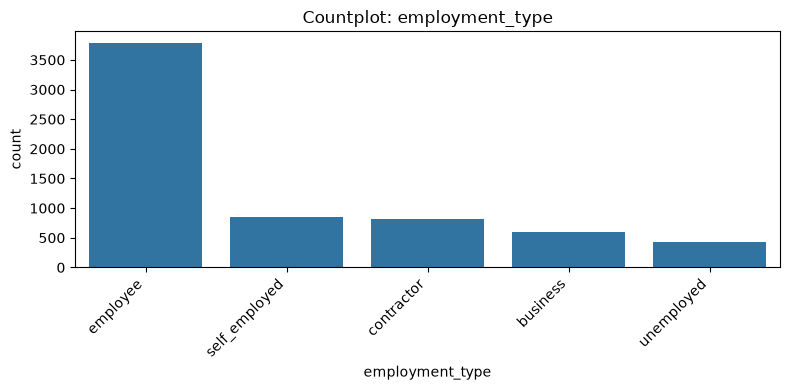

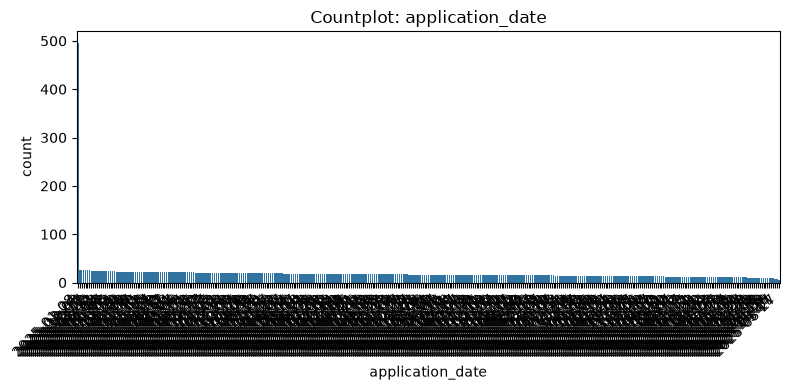

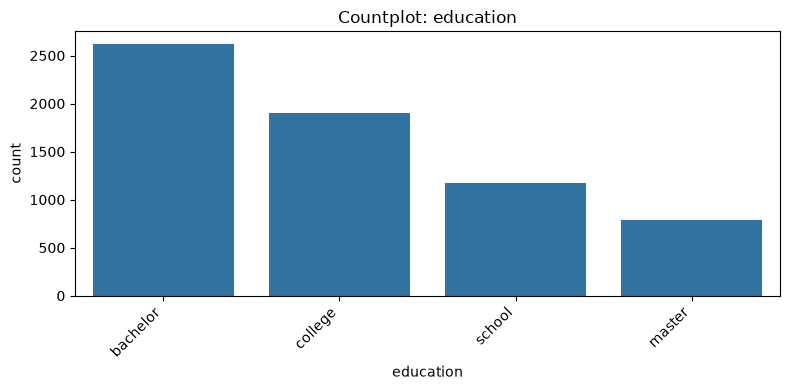

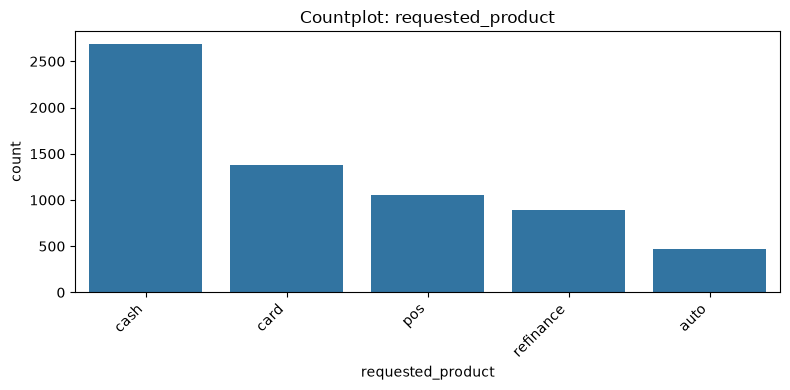

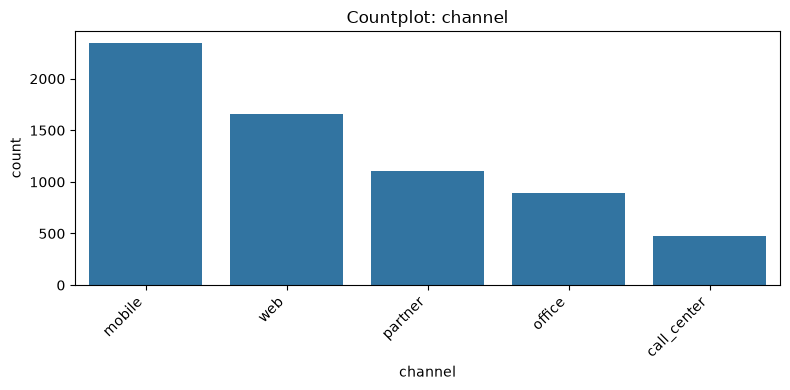

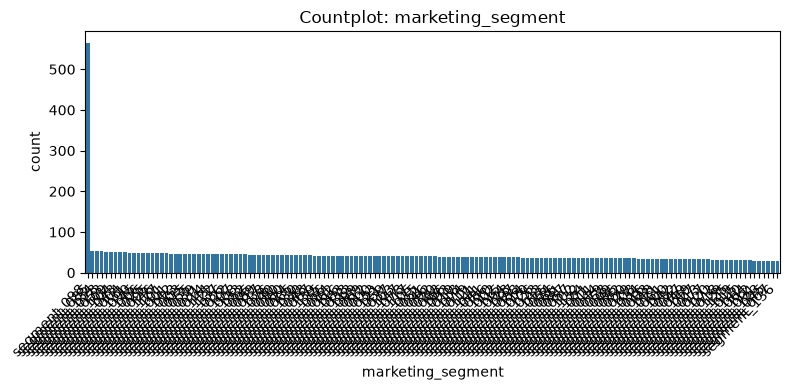

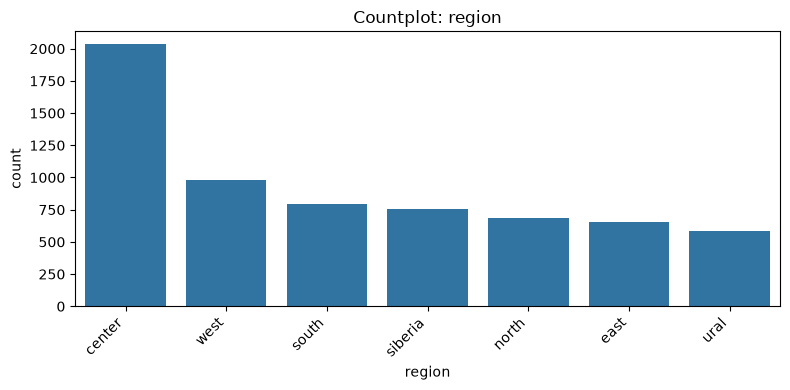

In [78]:
for col in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df_train,x=col,order=df_train[col].value_counts().index)

    plt.title(f'Countplot: {col}')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Для marketing_segment применим Frequency Encoding

### Применим One-hot encoding

In [79]:
cat_cols_encoding = ['employment_type','education','requested_product','channel','region']

df_train_encoding = pd.get_dummies(df_train, columns=cat_cols_encoding, dtype=int)
df_test_encoding = pd.get_dummies(df_test, columns=cat_cols_encoding, dtype=int)

freq = df_train["marketing_segment"].value_counts(normalize=True) #Frequency Encoding

df_train_encoding["marketing_segment"] = df_train["marketing_segment"].map(freq)
df_test_encoding["marketing_segment"] = df_test["marketing_segment"].map(freq).fillna(0)

In [80]:
df_train_encoding

,application_id,client_id,hash_id,region_coefficient_extended,age,incoming_amount,monthly_income,application_date,loan_amount,marketing_segment,region_coefficient,interest_rate,months_at_job,dependents,loan_term_months,siberia_northern_score,target,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,education_bachelor,education_college,education_master,education_school,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance,channel_call_center,channel_mobile,channel_office,channel_partner,channel_web,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west
0,107941,7941,61441390.0,1.0,37.0,30401.28,30401.28,2025-08-11,63464.49,0.005401,1.0,0.3062,31.0,0.0,24.0,0.336102,1,3.0,72210.10,24070.033333,148917.360,49639.120000,15.0,5.000000,1594.0,1110.0,1.0,2.0,1.0,1.0,1.0,0.0,0.0,1.0,20623.70,20623.7000,36.0,62.0,62.0,0.0,0.0,0.0,0.0,35.0,-66394.980,-1896.999429,9444.87,-6075.02,2.171429,5.0,14936.68,-81331.660,7.0,3.0,1.0,11.0,4.0,2.0,3.0,4.0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0
1,101163,1163,67321556.0,0.0,60.0,26024.64,26024.64,2025-12-29,113513.59,0.006481,1.0,0.1383,90.0,0.0,6.0,0.560893,1,5.0,269069.01,53813.802000,702481.490,140496.298000,60.0,12.400000,2184.0,821.0,5.0,0.0,0.0,0.0,4.0,0.0,1.0,1.0,20284.16,20284.1600,24.0,1235.0,1235.0,0.0,0.0,0.0,0.0,29.0,-38064.910,-1312.583103,18781.61,-9106.18,2.275862,5.0,27247.35,-65312.260,8.0,3.0,0.0,9.0,2.0,2.0,3.0,2.0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
2,100583,583,26719968.0,0.0,37.0,21389.83,21389.83,2025-11-09,48993.42,0.087191,1.0,0.1729,57.0,1.0,9.0,0.509329,0,1.0,9362.87,9362.870000,101951.690,101951.690000,7.0,7.000000,329.0,329.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,102193.73,51096.8650,6.0,1565.0,873.0,7.0,3.5,1.0,1.0,26.0,-36777.170,-1414.506538,-187.66,-6653.02,2.230769,5.0,0.00,-36777.170,6.0,3.0,0.0,10.0,2.0,0.0,2.0,3.0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1
3,104082,4082,45184358.0,0.0,44.0,31617.26,37717.51,2025-02-23,77765.78,0.006636,1.0,0.3585,19.0,0.0,36.0,0.509329,0,1.0,59731.91,59731.910000,84660.990,84660.990000,0.0,0.000000,2320.0,2320.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,141115.00,141115.0000,24.0,769.0,769.0,0.0,0.0,0.0,0.0,34.0,58973.660,1734.519412,54653.96,-5104.79,2.117647,5.0,108932.62,-49958.960,2.0,3.0,0.0,10.0,3.0,6.0,7.0,3.0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
4,108413,8413,58267524.0,0.0,60.0,18000.00,18000.00,2025-12-07,97254.10,0.006327,1.0,0.1472,405.0,0.0,9.0,0.741053,0,2.0,67273.84,27294.840000,165030.645,65932.865000,7.0,3.750000,2238.0,829.0,2.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,37376.14,37376.1400,24.0,1059.0,1059.0,0.0,0.0,0.0,0.0,33.0,-33647.990,-1019.636061,3257.70,-6482.34,2.121212,5.0,3257.70,-36905.690,9.0,3.0,1.0,8.0,4.0,1.0,6.0,1.0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,

In [81]:
df_test_encoding

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,months_at_job,monthly_income,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,application_date,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,education_bachelor,education_college,education_master,education_school,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance,channel_call_center,channel_mobile,channel_office,channel_partner,channel_web,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west
0,102531,2531,0.0,18.0,0.509329,55020645.5,73071.51,38.0,34183.79,34183.79,44.0,0.0,0.2146,0.004475,1.0,2025-04-25,6.0,283471.660,47245.276667,730777.300,121796.216667,90.0,16.333333,2878.0,435.0,4.0,2.0,1.0,1.0,3.0,1.0,0.0,1.0,51373.33,51373.3300,18.0,1202.0,1202.0,0.0,0.0,0.0,0.0,25.0,-2231.640,-89.265600,31596.13,-6097.08,2.460000,5.0,42322.66,-44554.300,0.0,5.0,1.0,9.0,1.0,3.0,4.0,2.0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,23.0,18645.00,18645.00,64.0,0.0,0.2851,0.007253,1.0,2025-05-07,3.0,105300.405,35100.135000,176139.640,58713.213333,7.0,5.000000,2172.0,497.0,2.0,1.0,0.0,0.0,2.0,0.0,1.0,2.0,151274.58,75637.2900,16.5,911.0,753.0,0.0,0.0,0.0,0.0,38.0,-10598.600,-278.910526,9944.85,-3697.95,2.157895,5.0,30691.14,-41289.740,5.0,6.0,1.0,10.0,4.0,4.0,5.0,3.0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0
2,100238,238,0.0,36.0,0.902039,92419982.0,67331.28,12.0,52931.84,52931.84,21.0,1.0,0.3810,0.006019,1.0,2025-02-26,1.0,25465.910,25465.910000,71929.370,71929.370000,7.0,7.000000,291.0,291.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,60434.71,60434.7100,18.0,422.0,422.0,0.0,0.0,0.0,0.0,45.0,-29585.490,-657.455333,33785.45,-24333.59,2.133333,5.0,125444.91,-155030.400,6.0,7.0,1.0,10.0,1.0,7.0,5.0,8.0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
3,104918,4918,0.0,6.0,0.737848,76137566.0,67331.28,179.0,37717.51,37301.16,55.0,0.0,0.1471,0.005556,1.0,2025-12-07,3.0,38604.760,12868.253333,42168.375,14056.125000,30.0,10.000000,1982.0,850.0,2.0,1.0,0.0,2.0,1.0,0.0,0.0,1.0,39366.47,39366.4700,9.0,823.0,823.0,0.0,0.0,0.0,0.0,32.0,-52640.780,-1645.024375,10817.56,-6636.68,2.375000,5.0,15592.27,-68233.050,6.0,1.0,1.0,11.0,3.0,2.0,2.0,6.0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,153.0,71928.29,71928.29,55.0,1.0,0.1840,0.006636,1.0,2025-05-09,2.0,117046.450,58523.225000,198814.870,99407.435000,60.0,30.000000,2626.0,522.0,2.0,0.0,0.0,1.0,1.0,0.0,0.0,3.0,148311.27,49437.0900,5.0,1111.0,40.0,0.0,0.0,0.0,0.0,50.0,9937.100,198.742000,94078.05,-23963.42,2.140000,5.0,219174.13,-209237.030,10.0,4.0,1.0,15.0,6.0,5.0,7.0,2.0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...

In [ ]:
# df_train_encoding.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/df_train_encoding_2.csv', index=False)
# df_test_encoding.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/df_test_encoding_2.csv', index=False)

# Удалим выбросы
Раздел создан с целью демонстрации удаления выбросов. Применяться в общем pipeline не будет. Это связано с тем, что выбросы в финансовом секторе не всегда являются выбросами. Иногда человек действительно может взять бОльший кредит, чем обычно

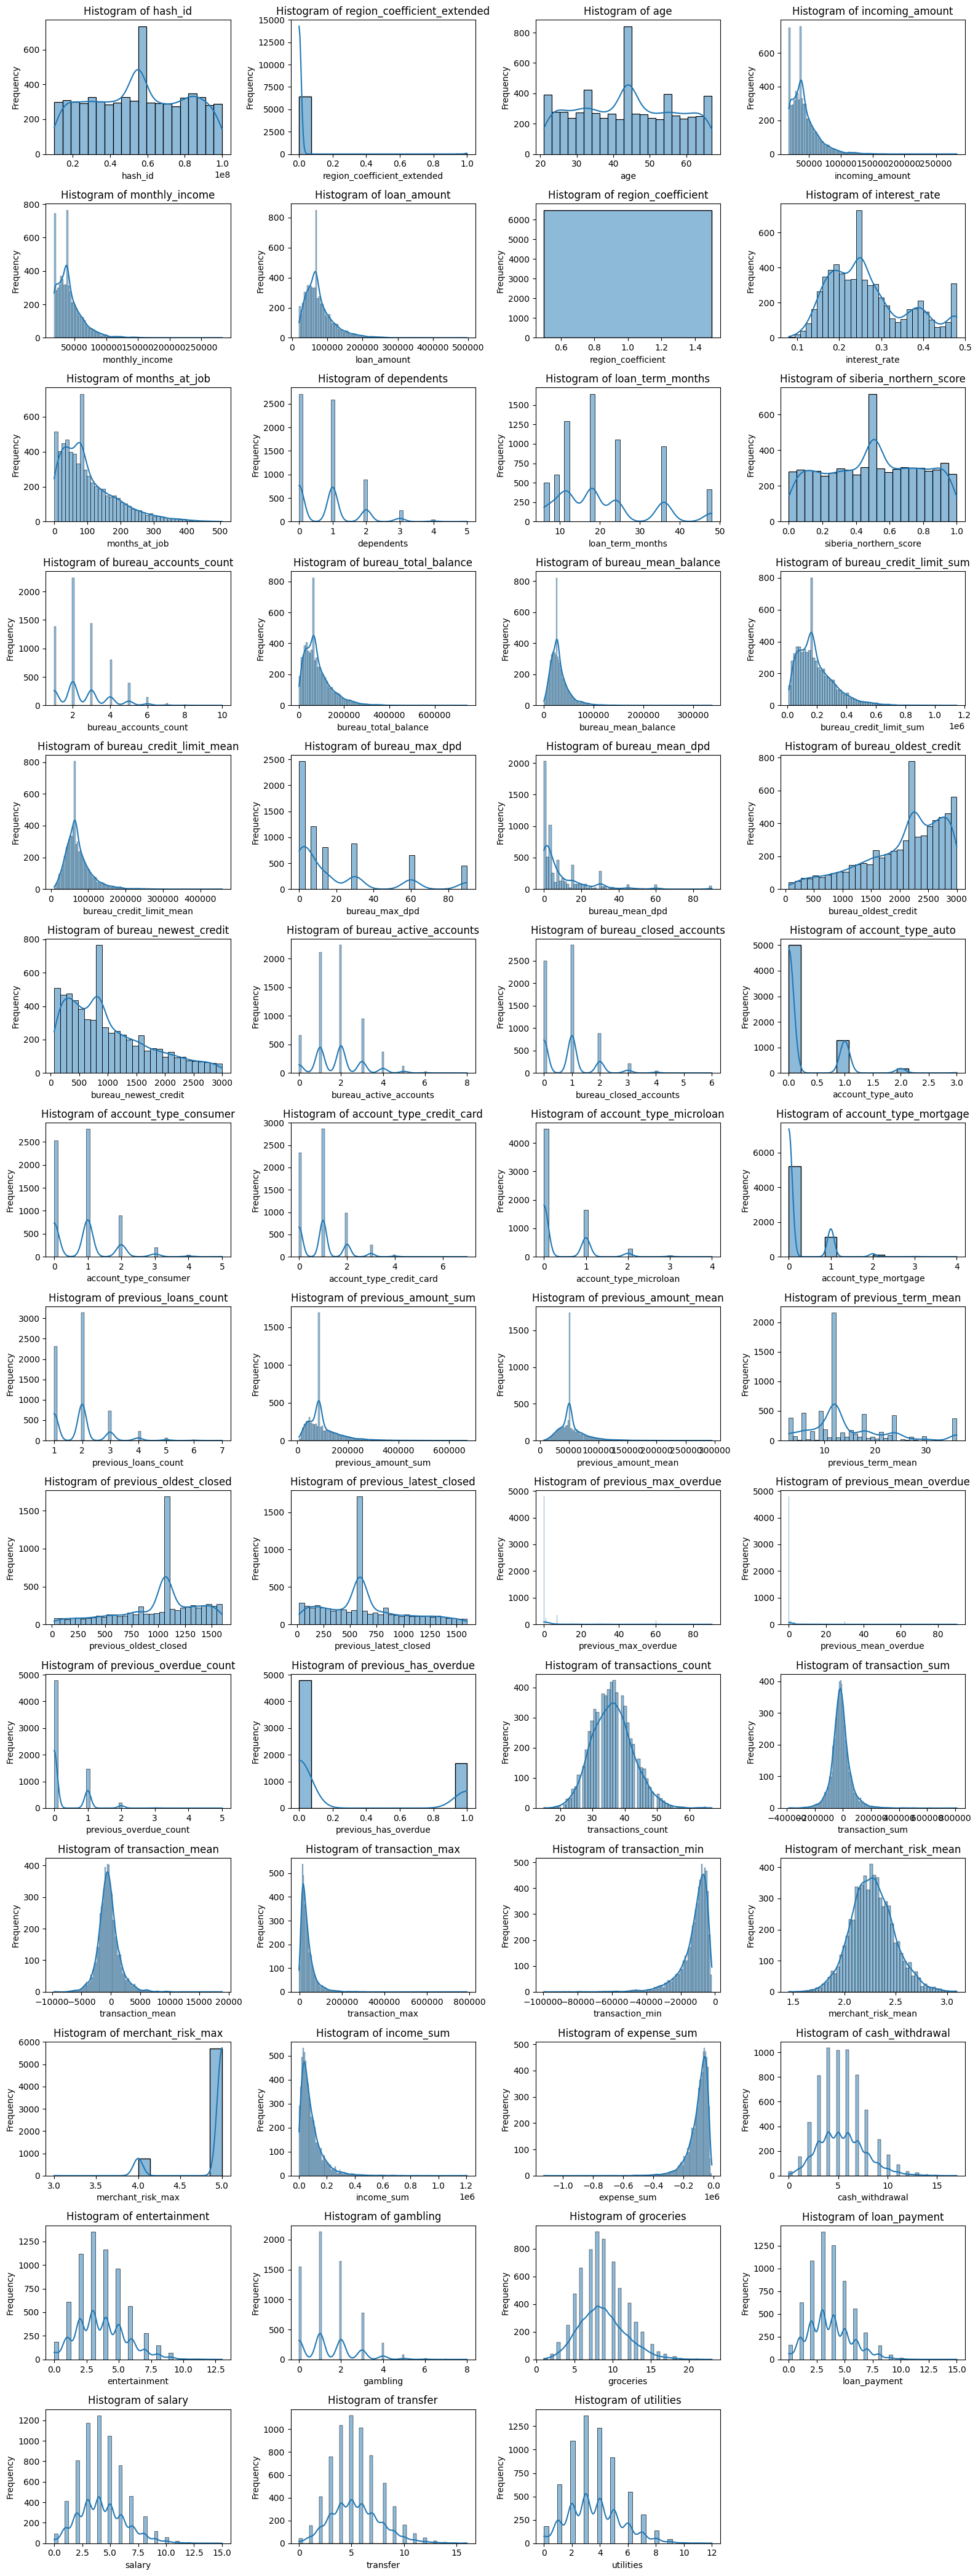

In [ ]:
# import math

# n_plots = len(num_cols)
# # Размер сетки графиков
# ncols = 4
# nrows = math.ceil(n_plots/ncols)

# # Размер каждого графика
# plt.figure(figsize=(4 * ncols, 3 * nrows))

# for i, col in enumerate(num_cols):
#     plt.subplot(nrows, ncols, i + 1)
#     sns.histplot(df_train[col], kde=True)
#     plt.title(f'Histogram of {col}')
#     plt.xlabel(col)
#     plt.ylabel('Frequency')

# plt.tight_layout()
# plt.show()

In [ ]:
# num_cols

Index(['hash_id', 'region_coefficient_extended', 'age', 'incoming_amount',
       'monthly_income', 'loan_amount', 'region_coefficient', 'interest_rate',
       'months_at_job', 'dependents', 'loan_term_months',
       'siberia_northern_score', 'bureau_accounts_count',
       'bureau_total_balance', 'bureau_mean_balance',
       'bureau_credit_limit_sum', 'bureau_credit_limit_mean', 'bureau_max_dpd',
       'bureau_mean_dpd', 'bureau_oldest_credit', 'bureau_newest_credit',
       'bureau_active_accounts', 'bureau_closed_accounts', 'account_type_auto',
       'account_type_consumer', 'account_type_credit_card',
       'account_type_microloan', 'account_type_mortgage',
       'previous_loans_count', 'previous_amount_sum', 'previous_amount_mean',
       'previous_term_mean', 'previous_oldest_closed',
       'previous_latest_closed', 'previous_max_overdue',
       'previous_mean_overdue', 'previous_overdue_count',
       'previous_has_overdue', 'transactions_count', 'transaction_sum',
    

In [ ]:
# incoming_amount monthly_income loan_amount bureau_total_balance bureau_mean_balance bureau_credit_limit_sum
# bureau_credit_limit_mean bureau_mean_dpd previous_amount_sum previous_amount_mean transaction_mean transaction_sum
# transaction_min transaction_max income_sum expense_sum

SyntaxError: invalid syntax (2010774248.py, line 1)

In [ ]:
# df_train.shape

(6480, 65)

In [ ]:
# columns_for_outlier_removal = [
#     'incoming_amount', 'monthly_income', 'loan_amount',
#     'bureau_total_balance', 'bureau_mean_balance', 'bureau_credit_limit_sum',
#     'bureau_credit_limit_mean', 'bureau_mean_dpd', 'previous_amount_sum',
#     'previous_amount_mean', 'transaction_mean', 'transaction_sum',
#     'transaction_min', 'transaction_max', 'income_sum', 'expense_sum'
# ]

# k_factor = 1.5 # Можно корректировать это значение для изменения порога удаления выбросов

# df_train_cleaned = df_train.copy()
# for col in columns_for_outlier_removal:
#     if col in df_train_cleaned.columns:
#         Q1 = df_train_cleaned[col].quantile(0.25)
#         Q3 = df_train_cleaned[col].quantile(0.75)
#         IQR = Q3 - Q1
#         lower_bound = Q1 - k_factor * IQR
#         upper_bound = Q3 + k_factor * IQR

#         # Filter out outliers
#         initial_shape = df_train_cleaned.shape[0]
#         df_train_cleaned = df_train_cleaned[(df_train_cleaned[col] >= lower_bound) & (df_train_cleaned[col] <= upper_bound)]
#         removed_rows = initial_shape - df_train_cleaned.shape[0]
#         print(f"Outliers removed for column: {col}. Removed {removed_rows} rows. New shape: {df_train_cleaned.shape}")

# print("\nDataFrame after outlier removal:")
# display(df_train_cleaned.shape)


Outliers removed for column: incoming_amount. Removed 280 rows. New shape: (6200, 65)
Outliers removed for column: monthly_income. Removed 82 rows. New shape: (6118, 65)
Outliers removed for column: loan_amount. Removed 309 rows. New shape: (5809, 65)
Outliers removed for column: bureau_total_balance. Removed 247 rows. New shape: (5562, 65)
Outliers removed for column: bureau_mean_balance. Removed 263 rows. New shape: (5299, 65)
Outliers removed for column: bureau_credit_limit_sum. Removed 96 rows. New shape: (5203, 65)
Outliers removed for column: bureau_credit_limit_mean. Removed 164 rows. New shape: (5039, 65)
Outliers removed for column: bureau_mean_dpd. Removed 307 rows. New shape: (4732, 65)
Outliers removed for column: previous_amount_sum. Removed 325 rows. New shape: (4407, 65)
Outliers removed for column: previous_amount_mean. Removed 372 rows. New shape: (4035, 65)
Outliers removed for column: transaction_mean. Removed 175 rows. New shape: (3860, 65)
Outliers removed for colu

(3313, 65)

# Обучение моделей классификации


In [ ]:
# df_train_encoding = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/df_train_encoding_2.csv')
# df_train_encoding

,application_id,client_id,hash_id,region_coefficient_extended,age,incoming_amount,monthly_income,application_date,loan_amount,marketing_segment,region_coefficient,interest_rate,months_at_job,dependents,loan_term_months,siberia_northern_score,target,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,education_bachelor,education_college,education_master,education_school,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance,channel_call_center,channel_mobile,channel_office,channel_partner,channel_web,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west
0,107941,7941,61441390.0,1.0,37.0,30401.28,30401.28,2025-08-11,63464.49,0.005401,1.0,0.3062,31.0,0.0,24.0,0.336102,1,3.0,72210.10,24070.033333,148917.360,49639.120000,15.0,5.000000,1594.0,1110.0,1.0,2.0,1.0,1.0,1.0,0.0,0.0,1.0,20623.70,20623.7000,36.0,62.0,62.0,0.0,0.0,0.0,0.0,35.0,-66394.980,-1896.999429,9444.87,-6075.02,2.171429,5.0,14936.68,-81331.660,7.0,3.0,1.0,11.0,4.0,2.0,3.0,4.0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0
1,101163,1163,67321556.0,0.0,60.0,26024.64,26024.64,2025-12-29,113513.59,0.006481,1.0,0.1383,90.0,0.0,6.0,0.560893,1,5.0,269069.01,53813.802000,702481.490,140496.298000,60.0,12.400000,2184.0,821.0,5.0,0.0,0.0,0.0,4.0,0.0,1.0,1.0,20284.16,20284.1600,24.0,1235.0,1235.0,0.0,0.0,0.0,0.0,29.0,-38064.910,-1312.583103,18781.61,-9106.18,2.275862,5.0,27247.35,-65312.260,8.0,3.0,0.0,9.0,2.0,2.0,3.0,2.0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
2,100583,583,26719968.0,0.0,37.0,21389.83,21389.83,2025-11-09,48993.42,0.087191,1.0,0.1729,57.0,1.0,9.0,0.509329,0,1.0,9362.87,9362.870000,101951.690,101951.690000,7.0,7.000000,329.0,329.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,102193.73,51096.8650,6.0,1565.0,873.0,7.0,3.5,1.0,1.0,26.0,-36777.170,-1414.506538,-187.66,-6653.02,2.230769,5.0,0.00,-36777.170,6.0,3.0,0.0,10.0,2.0,0.0,2.0,3.0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1
3,104082,4082,45184358.0,0.0,44.0,31617.26,37717.51,2025-02-23,77765.78,0.006636,1.0,0.3585,19.0,0.0,36.0,0.509329,0,1.0,59731.91,59731.910000,84660.990,84660.990000,0.0,0.000000,2320.0,2320.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,141115.00,141115.0000,24.0,769.0,769.0,0.0,0.0,0.0,0.0,34.0,58973.660,1734.519412,54653.96,-5104.79,2.117647,5.0,108932.62,-49958.960,2.0,3.0,0.0,10.0,3.0,6.0,7.0,3.0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
4,108413,8413,58267524.0,0.0,60.0,18000.00,18000.00,2025-12-07,97254.10,0.006327,1.0,0.1472,405.0,0.0,9.0,0.741053,0,2.0,67273.84,27294.840000,165030.645,65932.865000,7.0,3.750000,2238.0,829.0,2.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,37376.14,37376.1400,24.0,1059.0,1059.0,0.0,0.0,0.0,0.0,33.0,-33647.990,-1019.636061,3257.70,-6482.34,2.121212,5.0,3257.70,-36905.690,9.0,3.0,1.0,8.0,4.0,1.0,6.0,1.0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,

In [ ]:
# df_test_encoding = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/df_test_encoding_2.csv')
# df_test_encoding

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,months_at_job,monthly_income,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,application_date,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,education_bachelor,education_college,education_master,education_school,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance,channel_call_center,channel_mobile,channel_office,channel_partner,channel_web,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west
0,102531,2531,0.0,18.0,0.509329,55020645.5,73071.51,38.0,34183.79,34183.79,44.0,0.0,0.2146,0.004475,1.0,2025-04-25,6.0,283471.660,47245.276667,730777.300,121796.216667,90.0,16.333333,2878.0,435.0,4.0,2.0,1.0,1.0,3.0,1.0,0.0,1.0,51373.33,51373.3300,18.0,1202.0,1202.0,0.0,0.0,0.0,0.0,25.0,-2231.640,-89.265600,31596.13,-6097.08,2.460000,5.0,42322.66,-44554.300,0.0,5.0,1.0,9.0,1.0,3.0,4.0,2.0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,23.0,18645.00,18645.00,64.0,0.0,0.2851,0.007253,1.0,2025-05-07,3.0,105300.405,35100.135000,176139.640,58713.213333,7.0,5.000000,2172.0,497.0,2.0,1.0,0.0,0.0,2.0,0.0,1.0,2.0,151274.58,75637.2900,16.5,911.0,753.0,0.0,0.0,0.0,0.0,38.0,-10598.600,-278.910526,9944.85,-3697.95,2.157895,5.0,30691.14,-41289.740,5.0,6.0,1.0,10.0,4.0,4.0,5.0,3.0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0
2,100238,238,0.0,36.0,0.902039,92419982.0,67331.28,12.0,52931.84,52931.84,21.0,1.0,0.3810,0.006019,1.0,2025-02-26,1.0,25465.910,25465.910000,71929.370,71929.370000,7.0,7.000000,291.0,291.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,60434.71,60434.7100,18.0,422.0,422.0,0.0,0.0,0.0,0.0,45.0,-29585.490,-657.455333,33785.45,-24333.59,2.133333,5.0,125444.91,-155030.400,6.0,7.0,1.0,10.0,1.0,7.0,5.0,8.0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
3,104918,4918,0.0,6.0,0.737848,76137566.0,67331.28,179.0,37717.51,37301.16,55.0,0.0,0.1471,0.005556,1.0,2025-12-07,3.0,38604.760,12868.253333,42168.375,14056.125000,30.0,10.000000,1982.0,850.0,2.0,1.0,0.0,2.0,1.0,0.0,0.0,1.0,39366.47,39366.4700,9.0,823.0,823.0,0.0,0.0,0.0,0.0,32.0,-52640.780,-1645.024375,10817.56,-6636.68,2.375000,5.0,15592.27,-68233.050,6.0,1.0,1.0,11.0,3.0,2.0,2.0,6.0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,153.0,71928.29,71928.29,55.0,1.0,0.1840,0.006636,1.0,2025-05-09,2.0,117046.450,58523.225000,198814.870,99407.435000,60.0,30.000000,2626.0,522.0,2.0,0.0,0.0,1.0,1.0,0.0,0.0,3.0,148311.27,49437.0900,5.0,1111.0,40.0,0.0,0.0,0.0,0.0,50.0,9937.100,198.742000,94078.05,-23963.42,2.140000,5.0,219174.13,-209237.030,10.0,4.0,1.0,15.0,6.0,5.0,7.0,2.0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...

In [82]:
df_train_encoding['target'].value_counts(normalize=True)

target
0    0.657716
1    0.342284
Name: proportion, dtype: float64

In [83]:
df_train_encoding['application_date'] = pd.to_datetime(df_train_encoding['application_date'])
df_test_encoding['application_date'] = pd.to_datetime(df_test_encoding['application_date'])

In [84]:
df_train_encoding.info()

<class 'pandas.DataFrame'>
RangeIndex: 6480 entries, 0 to 6479
Data columns (total 86 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   application_id                 6480 non-null   int64         
 1   client_id                      6480 non-null   int64         
 2   hash_id                        6480 non-null   float64       
 3   region_coefficient_extended    6480 non-null   float64       
 4   age                            6480 non-null   float64       
 5   incoming_amount                6480 non-null   float64       
 6   monthly_income                 6480 non-null   float64       
 7   application_date               6480 non-null   datetime64[us]
 8   loan_amount                    6480 non-null   float64       
 9   marketing_segment              6480 non-null   float64       
 10  region_coefficient             6480 non-null   float64       
 11  interest_rate               

### Удалим столбцы с ID, application_date и target перед корреляционной матрицей и стандартизацией

In [85]:
df_target = df_train_encoding['target']
df_application_id = df_test_encoding['application_id']

In [86]:
df_train_encoding = df_train_encoding.drop(columns=['application_id','client_id','application_date','target'])
df_test_encoding = df_test_encoding.drop(columns=['application_id','client_id','application_date'])

### Correlation_matrix

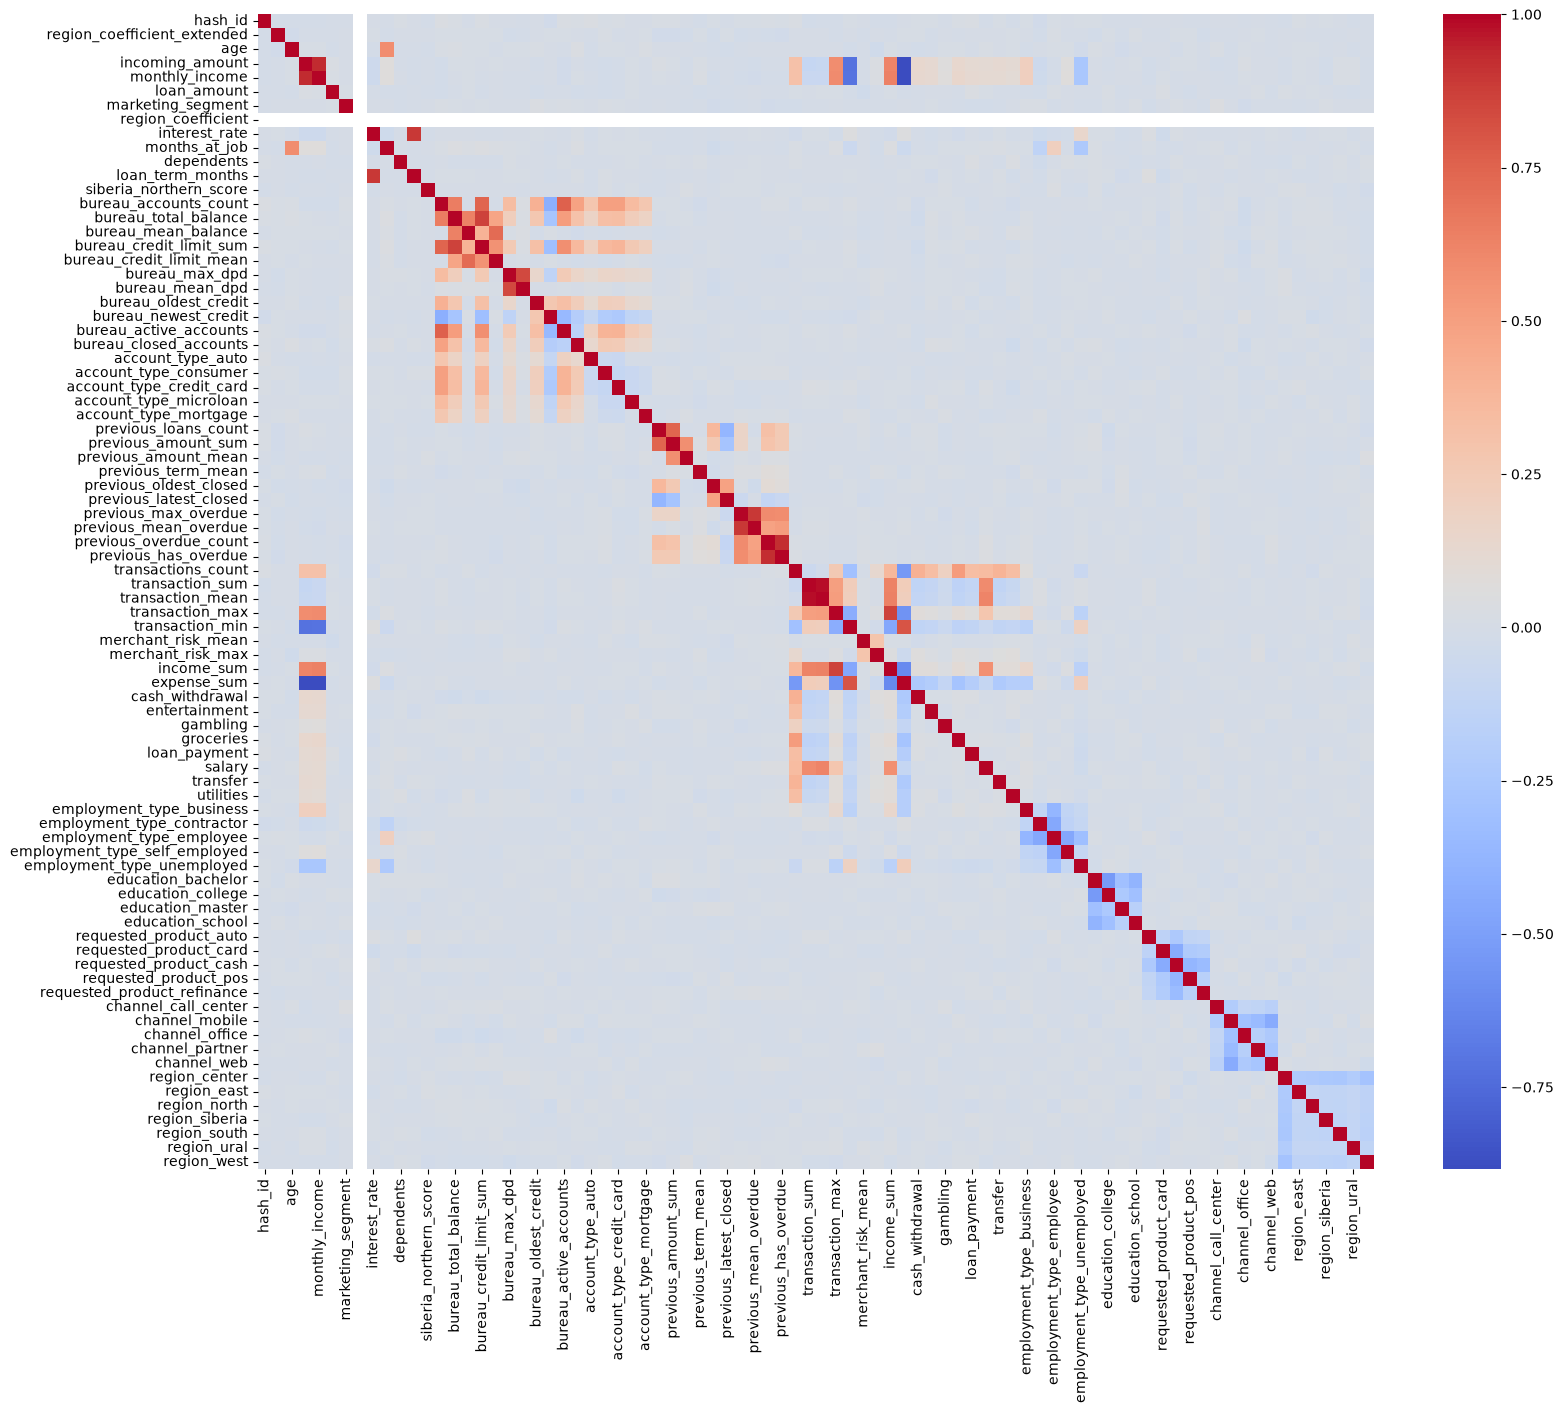

In [87]:
plt.figure(figsize=(18, 15))
sns.heatmap(df_train_encoding.corr(), cmap="coolwarm")
plt.show()

In [88]:
corr_matrix = df_train_encoding.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.80)]
print(to_drop)

['monthly_income', 'loan_term_months', 'bureau_credit_limit_sum', 'bureau_mean_dpd', 'previous_mean_overdue', 'previous_has_overdue', 'transaction_mean', 'income_sum', 'expense_sum']


In [89]:
df_train_encoding.drop(columns=to_drop, inplace=True)
df_test_encoding.drop(columns=to_drop, inplace=True)

In [90]:
df_train_encoding = pd.concat([df_train_encoding, df_target], axis=1)

In [91]:
df_train_encoding.columns

Index(['hash_id', 'region_coefficient_extended', 'age', 'incoming_amount',
       'loan_amount', 'marketing_segment', 'region_coefficient',
       'interest_rate', 'months_at_job', 'dependents',
       'siberia_northern_score', 'bureau_accounts_count',
       'bureau_total_balance', 'bureau_mean_balance',
       'bureau_credit_limit_mean', 'bureau_max_dpd', 'bureau_oldest_credit',
       'bureau_newest_credit', 'bureau_active_accounts',
       'bureau_closed_accounts', 'account_type_auto', 'account_type_consumer',
       'account_type_credit_card', 'account_type_microloan',
       'account_type_mortgage', 'previous_loans_count', 'previous_amount_sum',
       'previous_amount_mean', 'previous_term_mean', 'previous_oldest_closed',
       'previous_latest_closed', 'previous_max_overdue',
       'previous_overdue_count', 'transactions_count', 'transaction_sum',
       'transaction_max', 'transaction_min', 'merchant_risk_mean',
       'merchant_risk_max', 'cash_withdrawal', 'entertainment',

### Разделим данные на признаки в X и y с таргетной величиной

In [92]:
X = df_train_encoding.drop(columns=['target'])
y = df_train_encoding['target']
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X = X_scaled

df_test_encoding_aligned = df_test_encoding[X.columns]
X_test_scaled = pd.DataFrame(scaler.transform(df_test_encoding_aligned), columns=df_test_encoding_aligned.columns, index=df_test_encoding_aligned.index)
df_test_encoding_scaled = X_test_scaled

### Применим Cross-validation для сбалансированного обучения и упрощения оценки ROC AUC на нескольких фолдах

In [93]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [94]:
def evaluate_model(model, model_name):
    scores = []
    for fold, (train_idx, valid_idx) in enumerate(tqdm(cv.split(X, y),total=cv.n_splits,desc=f'{model_name} Cross-Validation')):
      X_train = X.iloc[train_idx]
      X_valid = X.iloc[valid_idx]
      y_train = y.iloc[train_idx]
      y_valid = y.iloc[valid_idx]
      model.fit(X_train, y_train)
      pred = model.predict_proba(X_valid)[:,1]
      score = roc_auc_score(y_valid, pred)
      scores.append(score)

    mean_score = np.mean(scores)
    print(f'Mean ROC-AUC for {model_name} = {mean_score:.5f}')
    return mean_score

In [95]:
cat_boost = CatBoostClassifier(iterations=2000,learning_rate=0.03,depth=6,l2_leaf_reg=5,loss_function='Logloss',eval_metric='AUC',random_seed=42,verbose=False)
log_reg = LogisticRegression(max_iter=2000,random_state=42)
xgb = XGBClassifier(n_estimators=1000,learning_rate=0.05,max_depth=6,subsample=0.8,colsample_bytree=0.8
                    ,eval_metric='logloss',random_state=42)
random_forest_clf = RandomForestClassifier(n_estimators=300,random_state=42,n_jobs=-1)
lg = LGBMClassifier(n_estimators=1000,learning_rate=0.05,max_depth=6,subsample=0.8,colsample_bytree=0.8
                    ,random_state=42, verbose=-1)

In [ ]:
models = {
    "LogisticRegression": log_reg,
    "RandomForest": random_forest_clf,
    "XGBoost": xgb,
    "CatBoost": cat_boost,
    "LightGBM": lg
}

results = {}
for model_name, model in models.items():
    results[model_name] = evaluate_model(model, model_name)

LogisticRegression Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for LogisticRegression = 0.81459


RandomForest Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for RandomForest = 0.80276


XGBoost Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for XGBoost = 0.80169


CatBoost Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for CatBoost = 0.80780


LightGBM Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for LightGBM = 0.79064


Лучший результат показала LogisticRegression. Попробуем провести настройку гиперпараметров, применим Optuna

### Настройка гиперпараметров с Optuna

In [ ]:
def objective(trial):

    model = LogisticRegression(
        C=trial.suggest_float("C", 1e-5, 100, log=True),
        max_iter=2000,
        random_state=42
    )

    return evaluate_model(model, "LogisticRegression")

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)

In [ ]:
print(study.best_params)
print(study.best_value)

{'C': 3.770453687147913}
0.8146041555443766


In [ ]:
def objective_rf(trial):

    model = RandomForestClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 500),
        max_depth=trial.suggest_int("max_depth", 3, 20),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
        random_state=42,
        n_jobs=-1
    )

    return evaluate_model(model, "RandomForest")

In [ ]:
study_rf = optuna.create_study(direction="maximize")
study_rf.optimize(objective_rf, n_trials=30)

In [ ]:
print(study_rf.best_params)
print(study_rf.best_value)

{'n_estimators': 346, 'max_depth': 14, 'min_samples_split': 8, 'min_samples_leaf': 7}
0.8066214642310807


In [ ]:
def objective_xgb(trial):

    model = XGBClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 1000),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        eval_metric="logloss",
        random_state=42
    )

    return evaluate_model(model, "XGBoost")

In [ ]:
study_xgb = optuna.create_study(direction="maximize")
study_xgb.optimize(objective_xgb, n_trials=30)

In [ ]:
print(study_xgb.best_params)
print(study_xgb.best_value)

{'n_estimators': 334, 'learning_rate': 0.03709014370668261, 'max_depth': 3, 'subsample': 0.6129591894424666, 'colsample_bytree': 0.5974041222843645}
0.8183694126214004


In [ ]:
def objective_cat(trial):

    model = CatBoostClassifier(
        iterations=trial.suggest_int("iterations", 300, 2000),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        depth=trial.suggest_int("depth", 4, 10),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1, 10),
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=False
    )

    return evaluate_model(model, "CatBoost")

In [ ]:
study_cat = optuna.create_study(direction="maximize")
study_cat.optimize(objective_cat, n_trials=30)

In [ ]:
print(study_cat.best_params)
print(study_cat.best_value)

{'iterations': 731, 'learning_rate': 0.016690317231983942, 'depth': 4, 'l2_leaf_reg': 2.6109378008996846}
0.8214033360381338


In [ ]:
def objective_lgb(trial):

    model = LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 1000),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        random_state=42,
        verbose=-1
    )

    return evaluate_model(model, "LightGBM")

In [ ]:
study_lgb = optuna.create_study(direction="maximize")
study_lgb.optimize(objective_lgb, n_trials=30)

In [ ]:
print(study_lgb.best_params)
print(study_lgb.best_value)

{'n_estimators': 647, 'learning_rate': 0.014217508755960905, 'max_depth': 3, 'subsample': 0.6075835995222028, 'colsample_bytree': 0.8006140769259188}
0.8163182639115029


In [ ]:
optimized_models = {
    "LogisticRegression": LogisticRegression(C=3.770453687147913, max_iter=2000, random_state=42),

    "RandomForest": RandomForestClassifier(n_estimators=346, max_depth=14, min_samples_split=8, min_samples_leaf=7, random_state=42, n_jobs=-1),

    "XGBoost": XGBClassifier(n_estimators=334, learning_rate=0.03709014370668261, max_depth=3, subsample=0.6129591894424666, colsample_bytree=0.5974041222843645, eval_metric="logloss", random_state=42),

    "CatBoost": CatBoostClassifier(iterations=731, learning_rate=0.016690317231983942, depth=4, l2_leaf_reg=2.6109378008996846, loss_function="Logloss", eval_metric="AUC", random_seed=42, verbose=False),

    "LightGBM": LGBMClassifier(n_estimators=647, learning_rate=0.014217508755960905, max_depth=3, subsample=0.6075835995222028, colsample_bytree=0.8006140769259188, random_state=42, verbose=-1)
}

results = {}

for model_name, model in optimized_models.items():
    results[model_name] = evaluate_model(model, model_name)

In [ ]:
results = {
    "LogisticRegression": 0.81460,
    "RandomForest": 0.8066,
    "XGBoost": 0.8184,
    "CatBoost": 0.8214,
    "LightGBM": 0.8163
}

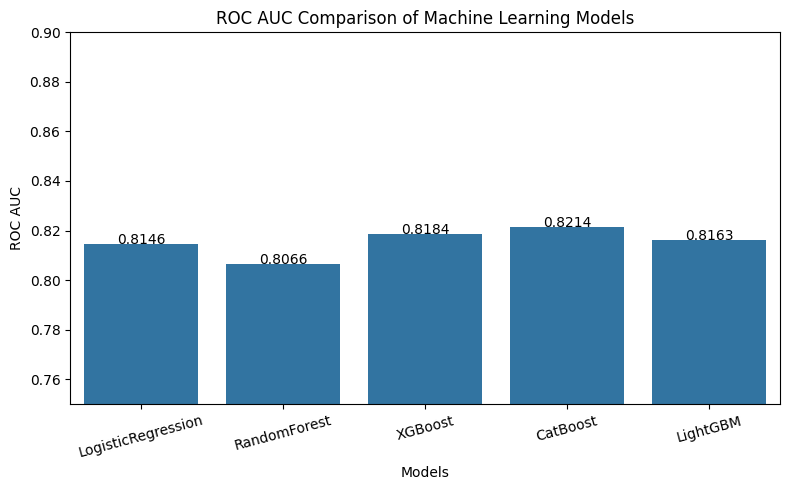

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=list(results.keys()), y=list(results.values()))

plt.title("ROC AUC Comparison of Machine Learning Models")
plt.xlabel("Models")
plt.ylabel("ROC AUC")
plt.ylim(0.75, 0.90)

for i, score in enumerate(results.values()):
    plt.text(i, score, f"{score:.4f}", ha="center")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### График обучения ROC AUC

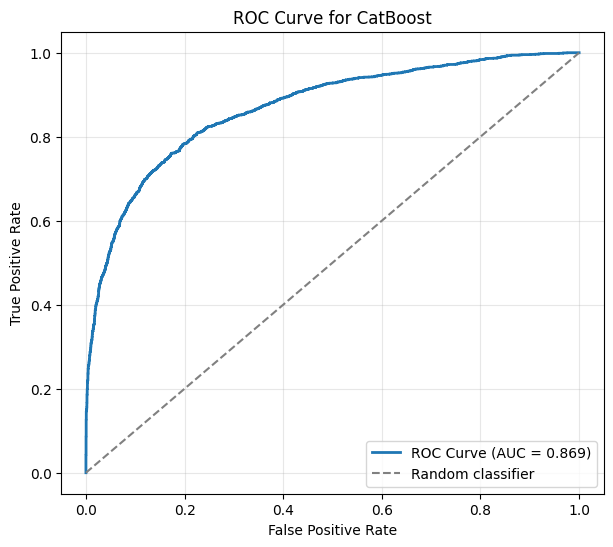

In [ ]:
from sklearn.metrics import roc_curve, auc

main_model = CatBoostClassifier(iterations=731, learning_rate=0.016690317231983942, depth=4, l2_leaf_reg=2.6109378008996846, loss_function="Logloss", eval_metric="AUC", random_seed=42, verbose=False)
main_model.fit(X, y)
pred = main_model.predict_proba(X)[:, 1]

fpr, tpr, thresholds = roc_curve(y, pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for CatBoost')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

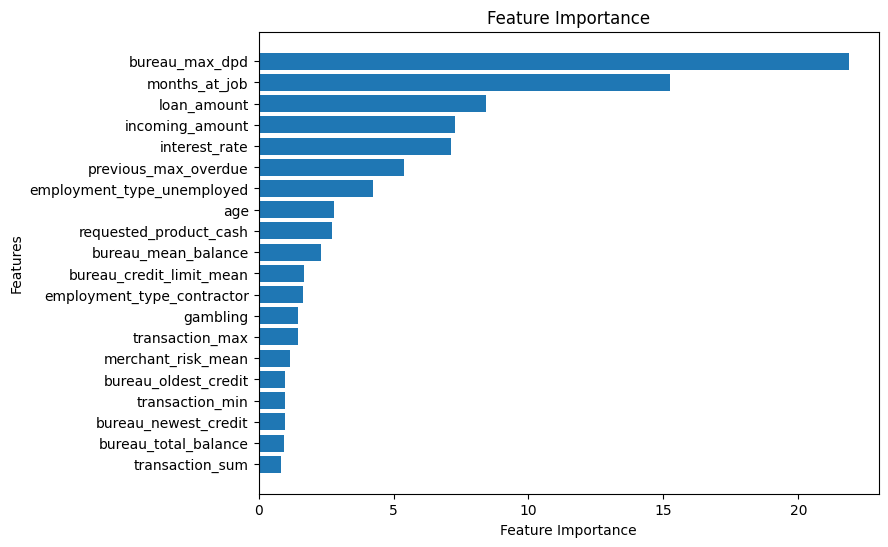

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": main_model.feature_importances_
})

importance = importance.sort_values("Importance", ascending=False).head(20)
importance = importance.sort_values("Importance")
plt.figure(figsize=(8, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Feature Importance")
plt.show()

Больше всего на модель влияет максимальное число дней просрочки платежей и сколько человек трудоустроено

### Финальное обучение

In [96]:
main_model = CatBoostClassifier(iterations=731, learning_rate=0.016690317231983942, depth=4, l2_leaf_reg=2.6109378008996846, loss_function="Logloss", eval_metric="AUC", random_seed=42, verbose=False)
main_model.fit(X,y)

CatBoostClassifier(depth=4, eval_metric='AUC', iterations=731, l2_leaf_reg=2.6109378008996846, learning_rate=0.016690317231983942, loss_function='Logloss', random_seed=42, verbose=False)

In [97]:
result_main_model = evaluate_model(main_model, "CatBoost")
print(result_main_model)

CatBoost Cross-Validation: 100%|██████████| 5/5 [00:32<00:00,  6.58s/it]

Mean ROC-AUC for CatBoost = 0.82169
0.8216905946767608


In [98]:
import joblib

joblib.dump(main_model, "Catboostmodel_credit_scoring.pkl")

['Catboostmodel_credit_scoring.pkl']

In [99]:
test_pred = main_model.predict_proba(df_test_encoding_scaled)[:,1]

In [100]:
submission = pd.DataFrame({"application_id": df_application_id,"target": test_pred})

submission

,application_id,target
0,102531,0.830924
1,107213,0.602297
2,100238,0.152071
3,104918,0.233817
4,106480,0.389174
...,...,...
2515,105735,0.338666
2516,105192,0.424631
2517,105391,0.259468
2518,100861,0.415227


In [ ]:
submission.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/submission_2.csv', index=False)